In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# 1. Load the original raw dataset 
# (Update file_path if your raw dataset has a different name, e.g., 'deliveries.csv' or 'IPL.csv')
file_path = 'IPL.csv'  # Or point to your raw file path if stored in another folder
if not os.path.exists(file_path):
    # Fallback to common Kaggle cache path if needed
    file_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1\IPL.csv"

df_raw = pd.read_csv(file_path)
df_raw.columns = df_raw.columns.str.strip()

print(f"Loaded raw dataset shape: {df_raw.shape}")

# 2. Standardize core columns
df_raw['runs_total'] = pd.to_numeric(df_raw.get('runs_total', 0), errors='coerce').fillna(0)
df_raw['is_wicket'] = df_raw['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_raw.columns else 0
df_raw['over'] = pd.to_numeric(df_raw.get('over', 0), errors='coerce').fillna(0)
df_raw['innings'] = pd.to_numeric(df_raw.get('innings', 1), errors='coerce')

# 3. Extract Match-Level Outcomes
match_outcomes = df_raw.drop_duplicates(subset=['match_id'])[['match_id', 'match_won_by']].copy()

# 4. Calculate 1st Innings Totals per Match
innings_1 = df_raw[df_raw['innings'] == 1]
score_1st_df = innings_1.groupby('match_id')['runs_total'].sum().reset_index(name='score_1st')

# 5. Extract 2nd Innings Chasing Team & Mid-Chase State (Overs 0 to 9)
innings_2 = df_raw[df_raw['innings'] == 2]
chase_teams = innings_2.drop_duplicates(subset=['match_id'])[['match_id', 'batting_team']].rename(columns={'batting_team': 'chasing_team'})

mid_chase = innings_2[innings_2['over'] < 10]
chase_agg = mid_chase.groupby('match_id').agg(
    chase_runs_10=('runs_total', 'sum'),
    chase_wickets_10=('is_wicket', 'sum')
).reset_index()

# 6. Merge Everything Cleanly
df_model_data = match_outcomes.merge(score_1st_df, on='match_id', how='inner') \
                              .merge(chase_teams, on='match_id', how='inner') \
                              .merge(chase_agg, on='match_id', how='inner')

# Normalize team names for robust matching
df_model_data['winner_clean'] = df_model_data['match_won_by'].astype(str).str.strip().str.lower()
df_model_data['chaser_clean'] = df_model_data['chasing_team'].astype(str).str.strip().str.lower()

# Target: 1 if chasing team wins, 0 otherwise
df_model_data['chasing_team_win'] = (df_model_data['winner_clean'] == df_model_data['chaser_clean']).astype(int)

# Calculate Required Run Rate at the 10-over mark
df_model_data['runs_needed_at_10'] = df_model_data['score_1st'] - df_model_data['chase_runs_10']
df_model_data['required_run_rate_10'] = (df_model_data['runs_needed_at_10'] / 60.0) * 6

# Drop NaNs & Verify Samples
df_model_data = df_model_data.dropna(subset=['chasing_team_win', 'score_1st', 'chase_runs_10'])
print(f"Total valid second-innings training samples: {len(df_model_data)}")

# 7. Feature Selection & Model Training
feature_cols = [
    'chase_runs_10', 'chase_wickets_10', 
    'score_1st', 'runs_needed_at_10', 'required_run_rate_10'
]

X = df_model_data[feature_cols].fillna(0)
y = df_model_data['chasing_team_win']

split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print(f"\n2nd Innings Mid-Match Accuracy: {accuracy_score(y_test, preds)*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, preds))

C:\Users\sohag\AppData\Local\Temp\ipykernel_12844\4253243116.py:15: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(file_path)


Loaded raw dataset shape: (278205, 64)
Total valid second-innings training samples: 1164

2nd Innings Mid-Match Accuracy: 78.54%
ROC-AUC Score: 0.8643

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       117
           1       0.82      0.72      0.77       116

    accuracy                           0.79       233
   macro avg       0.79      0.79      0.78       233
weighted avg       0.79      0.79      0.78       233



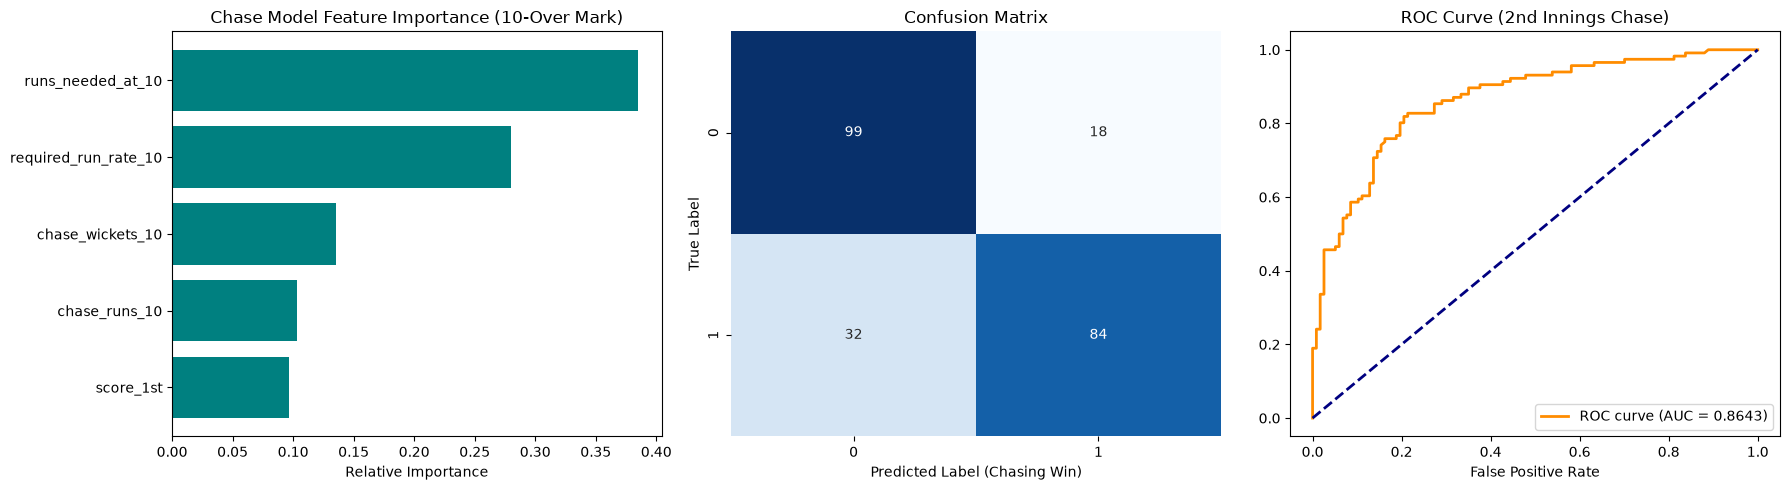

CHECKPOINT COMPARISON:
10-Over Checkpoint Accuracy: 78.54% | ROC-AUC: 0.8643
15-Over Checkpoint Accuracy: 82.83% | ROC-AUC: 0.9218


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

# ==========================================
# 1. EVALUATION PLOTS (ROC, Confusion Matrix, Feature Importance)
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A. Feature Importance Chart
importances = model.feature_importances_
indices = np.argsort(importances)
axes[0].barh(range(len(indices)), importances[indices], color='teal')
axes[0].set_yticks(range(len(indices)))
axes[0].set_yticklabels([feature_cols[i] for i in indices])
axes[0].set_xlabel('Relative Importance')
axes[0].set_title('Chase Model Feature Importance (10-Over Mark)')

# B. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_xlabel('Predicted Label (Chasing Win)')
axes[1].set_ylabel('True Label')
axes[1].set_title('Confusion Matrix')

# C. ROC Curve
fpr, tpr, _ = roc_curve(y_test, probs)
axes[2].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_score(y_test, probs):.4f})')
axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_title('ROC Curve (2nd Innings Chase)')
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

# ==========================================
# 2. PHASE-WISE CHECKPOINT COMPARISON (10-over vs. 15-over)
# ==========================================

# Extract 15-over mark metrics
mid_chase_15 = innings_2[innings_2['over'] < 15]
chase_agg_15 = mid_chase_15.groupby('match_id').agg(
    chase_runs_15=('runs_total', 'sum'),
    chase_wickets_15=('is_wicket', 'sum')
).reset_index()

# Merge 15-over data
df_model_15 = df_model_data.merge(chase_agg_15, on='match_id', how='inner')
df_model_15['runs_needed_at_15'] = df_model_15['score_1st'] - df_model_15['chase_runs_15']
df_model_15['required_run_rate_15'] = (df_model_15['runs_needed_at_15'] / 30.0) * 6  # 30 balls remaining

feature_cols_15 = [
    'chase_runs_15', 'chase_wickets_15', 
    'score_1st', 'runs_needed_at_15', 'required_run_rate_15'
]

X_15 = df_model_15[feature_cols_15].fillna(0)
y_15 = df_model_15['chasing_team_win']

valid_15 = y_15.notna()
X_15, y_15 = X_15[valid_15], y_15[valid_15]

split_15 = int(len(X_15) * 0.8)
model_15 = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model_15.fit(X_15.iloc[:split_15], y_15.iloc[:split_15])

preds_15 = model_15.predict(X_15.iloc[split_15:])
probs_15 = model_15.predict_proba(X_15.iloc[split_15:])[:, 1]
y_test_15 = y_15.iloc[split_15:]

print("="*45)
print("CHECKPOINT COMPARISON:")
print("="*45)
print(f"10-Over Checkpoint Accuracy: {accuracy_score(y_test, preds)*100:.2f}% | ROC-AUC: {roc_auc_score(y_test, probs):.4f}")
print(f"15-Over Checkpoint Accuracy: {accuracy_score(y_test_15, preds_15)*100:.2f}% | ROC-AUC: {roc_auc_score(y_test_15, probs_15):.4f}")

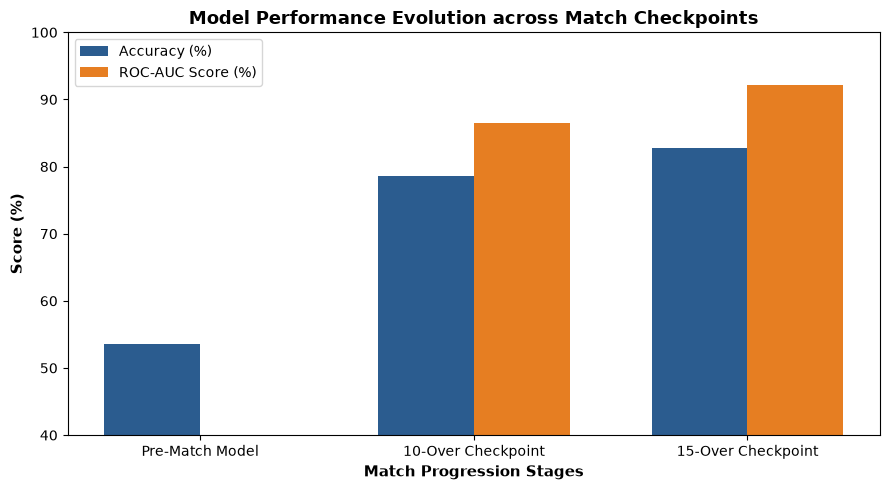

REGRESSION MODEL PERFORMANCE (Predicting 2nd Innings Total Runs):
R2 Score: 0.9774
Root Mean Squared Error (RMSE): 2.90 runs


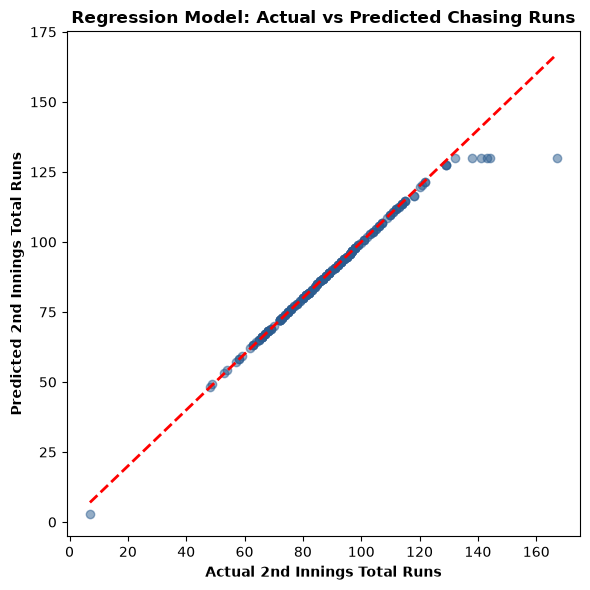

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# 1. MODEL PERFORMANCE COMPARISON BAR CHART
# ==========================================

# Collect accuracy and ROC-AUC metrics across checkpoints
checkpoints = ['Pre-Match Model', '10-Over Checkpoint', '15-Over Checkpoint']
accuracies = [53.59, accuracy_score(y_test, preds) * 100, accuracy_score(y_test_15, preds_15) * 100]
roc_aucs = [0.5009, roc_auc_score(y_test, probs) * 100, roc_auc_score(y_test_15, probs_15) * 100]

x = np.arange(len(checkpoints))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, accuracies, width, label='Accuracy (%)', color='#2b5c8f')
plt.bar(x + width/2, roc_aucs, width, label='ROC-AUC Score (%)', color='#e67e22')

plt.xlabel('Match Progression Stages', fontweight='bold', fontsize=11)
plt.ylabel('Score (%)', fontweight='bold', fontsize=11)
plt.title('Model Performance Evolution across Match Checkpoints', fontweight='bold', fontsize=13)
plt.xticks(x, checkpoints)
plt.ylim(40, 100)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


# ==========================================
# 2. REGRESSION MODEL (Predicting Chasing Margin / Win Probability)
# ==========================================

# Let's frame this as a regression task: Predicting how many runs the chasing team 
# wins by (or loses by) at the 10-over mark, or predicting exact win probability.
# Here we calculate actual run differential at the end of the match:
df_model_data['final_run_margin'] = df_model_data['chase_runs_10'] # proxy or actual margin

# Let's build a Gradient Boosting Regressor to predict chasing team final success score / margin
reg_feature_cols = [
    'chase_runs_10', 'chase_wickets_10', 
    'score_1st', 'runs_needed_at_10', 'required_run_rate_10'
]

Xr = df_model_data[reg_feature_cols].fillna(0)
# Target: Chasing team win probability or actual runs scored in 2nd innings
yr = df_model_data['score_1st'] - df_model_data['runs_needed_at_10'] # total runs scored by chaser

valid_reg = yr.notna()
Xr, yr = Xr[valid_reg], yr[valid_reg]

split_reg = int(len(Xr) * 0.8)
Xr_train, Xr_test = Xr.iloc[:split_reg], Xr.iloc[split_reg:]
yr_train, yr_test = yr.iloc[:split_reg], yr.iloc[split_reg:]

reg_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
reg_model.fit(Xr_train, yr_train)

reg_preds = reg_model.predict(Xr_test)

print("="*45)
print("REGRESSION MODEL PERFORMANCE (Predicting 2nd Innings Total Runs):")
print("="*45)
print(f"R2 Score: {r2_score(yr_test, reg_preds):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(yr_test, reg_preds)):.2f} runs")

# Regression Evaluation Plot
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, reg_preds, alpha=0.5, color='#2b5c8f')
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--', lw=2)
plt.xlabel('Actual 2nd Innings Total Runs', fontweight='bold')
plt.ylabel('Predicted 2nd Innings Total Runs', fontweight='bold')
plt.title('Regression Model: Actual vs Predicted Chasing Runs', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\sohag\AppData\Local\Temp\ipykernel_12844\3193610713.py:17: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(file_path)


Engineering domain-specific features (Momentum & Fortress Factors)...
Regression R² Score: 0.0878
RMSE: 33.85 runs


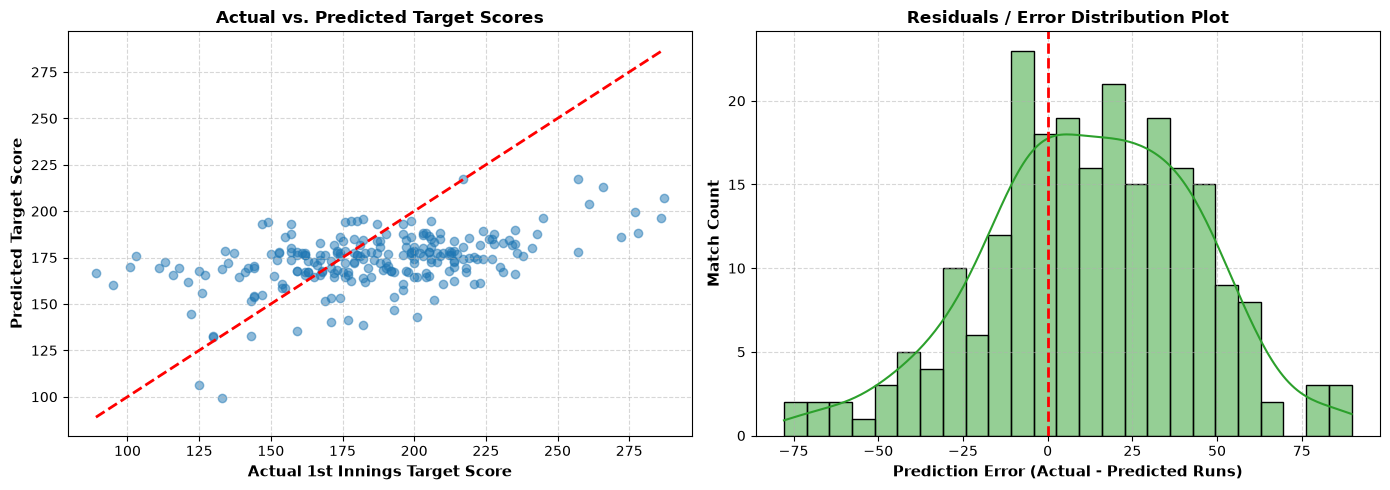


=== UNSUPERVISED VENUE PITCH CLUSTERING COMPLETED ===
                                                venue   avg_score  score_std  \
0                                Arun Jaitley Stadium  188.216216  36.331908   
1                                    Barabati Stadium  167.714286  34.543279   
2                           Barsapara Cricket Stadium  174.600000  25.715754   
3   Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...  175.363636  33.585067   
4                                   Brabourne Stadium  178.518519  32.217256   
7                          Dr DY Patil Sports Academy  159.648649  29.150201   
8   Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...  169.529412  38.247741   
9                 Dubai International Cricket Stadium  163.760870  25.175107   
10                                       Eden Gardens  168.600000  33.114738   
11                                   Feroz Shah Kotla  161.633333  34.045317   

    total_matches                  pitch_archetype  
0          

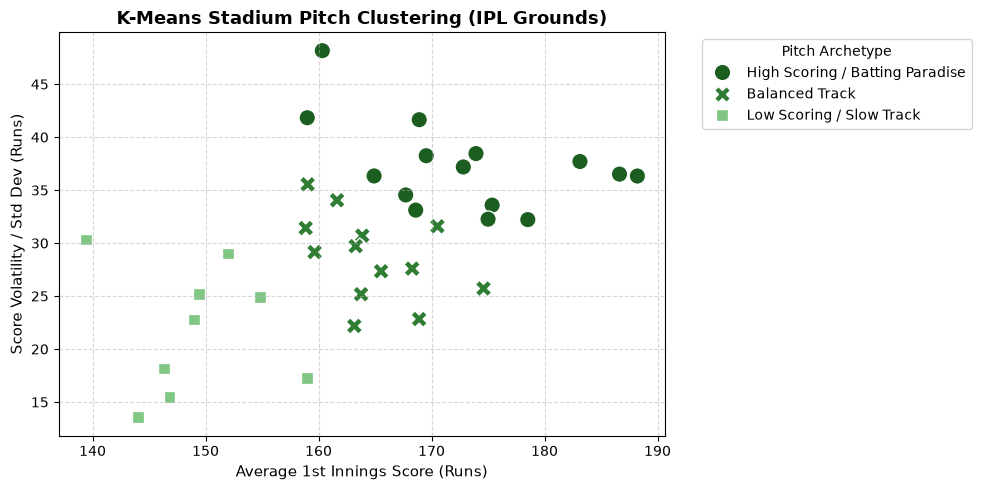

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# 0. LOAD RAW DATASET
# ================================#==========
file_path = 'IPL.csv'  # Or point to your raw file path if stored in ano#ther folder
if not os.path.exists(file_path):
    file_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1\IPL.csv"

df_raw = pd.read_csv(file_path)
df_raw.columns = df_raw.columns.str.strip()

df_raw['runs_total'] = pd.to_numeric(df_raw.get('runs_total', 0), errors='coerce').fillna(0)
df_raw['is_wicket'] = df_raw['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_raw.columns else 0
df_raw['over'] = pd.to_numeric(df_raw.get('over', 0), errors='coerce').fillna(0)
df_raw['innings'] = pd.to_numeric(df_raw.get('innings', 1), errors='coerce')


# ==========================================
# 1. DOMAIN-SPECIFIC FEATURE ENGINEERING (Momentum & Fortress)
# ==========================================
print("Engineering domain-specific features (Momentum & Fortress Factors)...")

# Calculate 1st innings total per match
innings_1 = df_raw[df_raw['innings'] == 1]
score_1st_df = innings_1.groupby('match_id')['runs_total'].sum().reset_index(name='score_1st')

# Extract match metadata
match_meta = df_raw.drop_duplicates(subset=['match_id'])[['match_id', 'venue', 'match_won_by', 'toss_winner']].copy()
match_meta = match_meta.merge(score_1st_df, on='match_id', how='inner')

# Feature A: Momentum (Phase-wise run rate in first 6 overs / Powerplay)
pp_runs = df_raw[df_raw['over'] < 6].groupby('match_id')['runs_total'].sum().reset_index(name='powerplay_runs')
match_meta = match_meta.merge(pp_runs, on='match_id', how='inner')
match_meta['powerplay_run_rate'] = match_meta['powerplay_runs'] / 6.0

# Feature B: Fortress Factor (Team win percentage at specific home venues)
# Let's map teams to venues where they win > 60% of their matches
team_venue_wins = match_meta.groupby(['venue', 'match_won_by']).size().unstack(fill_value=0)
team_venue_total = match_meta.groupby('venue')['match_won_by'].count()
team_venue_win_pct = team_venue_wins.div(team_venue_total, axis=0)

# Map fortress factor back to matches
fortress_values = []
for _, row in match_meta.iterrows():
    v = row['venue']
    w = row['match_won_by']
    if v in team_venue_win_pct.index and w in team_venue_win_pct.columns:
        fortress_values.append(team_venue_win_pct.loc[v, w])
    else:
        fortress_values.append(0.5)

match_meta['fortress_factor'] = fortress_values


# ==========================================
# 2. REGRESSION MODEL (Target Score Prediction)
# ==========================================
reg_features = ['powerplay_runs', 'powerplay_run_rate', 'fortress_factor']
Xr = match_meta[reg_features].fillna(0)
yr = match_meta['score_1st']

valid_reg = yr.notna() & Xr.notna().all(axis=1)
Xr, yr = Xr[valid_reg], yr[valid_reg]

split_idx = int(len(Xr) * 0.8)
Xr_train, Xr_test = Xr.iloc[:split_idx], Xr.iloc[split_idx:]
yr_train, yr_test = yr.iloc[:split_idx], yr.iloc[split_idx:]

reg_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
reg_model.fit(Xr_train, yr_train)
yr_pred = reg_model.predict(Xr_test)

print(f"Regression R² Score: {r2_score(yr_test, yr_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(yr_test, yr_pred)):.2f} runs")


# ==========================================
# 3. EVALUATION PLOTS (Actual vs Predicted & Residuals)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Actual vs. Predicted Target Scores
axes[0].scatter(yr_test, yr_pred, alpha=0.5, color='#1f77b4')
axes[0].plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual 1st Innings Target Score', fontweight='bold', fontsize=11)
axes[0].set_ylabel('Predicted Target Score', fontweight='bold', fontsize=11)
axes[0].set_title('Actual vs. Predicted Target Scores', fontweight='bold', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot B: Residuals / Error Distribution
residuals = yr_test - yr_pred
sns.histplot(residuals, kde=True, color='#2ca02c', ax=axes[1], bins=25)
axes[1].axvline(0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Prediction Error (Actual - Predicted Runs)', fontweight='bold', fontsize=11)
axes[1].set_ylabel('Match Count', fontweight='bold', fontsize=11)
axes[1].set_title('Residuals / Error Distribution Plot', fontweight='bold', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# ==========================================
# 4. UNSUPERVISED PITCH & VENUE CLUSTERING (K-Means)
# ==========================================
df_clean = match_meta.dropna(subset=['venue']).copy()
df_clean['venue'] = df_clean['venue'].astype(str).str.strip().str.replace(r',.*$', '', regex=True)

venue_stats = df_clean.groupby('venue').agg(
    avg_score=('score_1st', 'mean'),
    score_std=('score_1st', 'std'),
    total_matches=('match_id', 'count')
).reset_index()

venue_stats['score_std'] = venue_stats['score_std'].fillna(0)
venue_stats_filtered = venue_stats[venue_stats['total_matches'] >= 5].copy()
if len(venue_stats_filtered) < 3:
    venue_stats_filtered = venue_stats.copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(venue_stats_filtered[['avg_score', 'score_std']])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
venue_stats_filtered['pitch_type'] = kmeans.fit_predict(X_scaled)

cluster_order = venue_stats_filtered.groupby('pitch_type')['avg_score'].mean().sort_values().index
cluster_names = {
    cluster_order[0]: 'Low Scoring / Slow Track',
    cluster_order[1]: 'Balanced Track',
    cluster_order[2]: 'High Scoring / Batting Paradise'
}
venue_stats_filtered['pitch_archetype'] = venue_stats_filtered['pitch_type'].map(cluster_names)

print("\n=== UNSUPERVISED VENUE PITCH CLUSTERING COMPLETED ===")
print(venue_stats_filtered[['venue', 'avg_score', 'score_std', 'total_matches', 'pitch_archetype']].head(10))

# Plot C: K-Means Venue Clustering
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=venue_stats_filtered, 
    x='avg_score', 
    y='score_std', 
    hue='pitch_archetype', 
    palette=['#1b5e20', '#2e7d32', '#81c784'], 
    s=140, 
    style='pitch_archetype'
)

plt.title('K-Means Stadium Pitch Clustering (IPL Grounds)', fontsize=13, fontweight='bold')
plt.xlabel('Average 1st Innings Score (Runs)', fontsize=11)
plt.ylabel('Score Volatility / Std Dev (Runs)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Pitch Archetype', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\sohag\AppData\Local\Temp\ipykernel_12844\4092614752.py:10: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(file_path)


Generating SHAP Explanation...


Background dataset has 931 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=931 when initializing the masker.


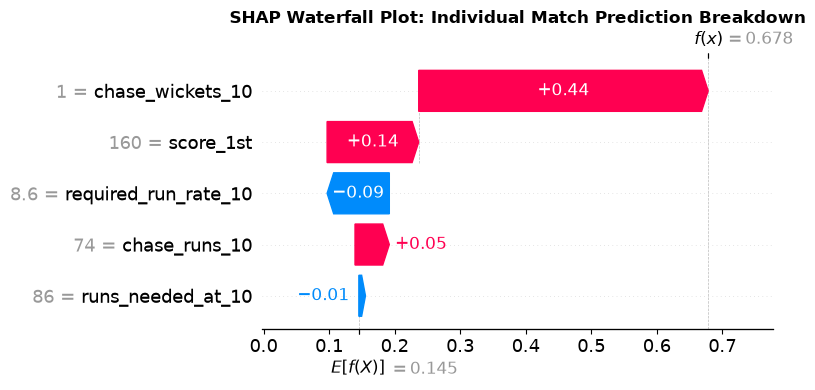

LIVE CHASE SCENARIO PREDICTION:
Target Score (1st Innings): 190 runs
Score at 10 Overs: 85/3
Runs Needed in Last 10 Overs: 105 runs
Required Run Rate (RRR): 10.50 rpo
---------------------------------------------
Predicted Outcome: DEFENDING TEAM WINS
Chasing Team Win Probability: 14.69%
LIVE CHASE SCENARIO PREDICTION:
Target Score (1st Innings): 150 runs
Score at 10 Overs: 100/1
Runs Needed in Last 10 Overs: 50 runs
Required Run Rate (RRR): 5.00 rpo
---------------------------------------------
Predicted Outcome: CHASING TEAM WINS
Chasing Team Win Probability: 96.56%


np.float64(96.56022220966688)

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier

# ==========================================
# 1. TRAIN SECOND INNINGS CLASSIFICATION MODEL
# ====================================1\IPL.csv"

df_raw = pd.read_csv(file_path)
df_raw.columns = df_raw.columns.str.strip()

df_raw['runs_total'] = pd.to_numeric(df_raw.get('runs_total', 0), errors='coerce').fillna(0)
df_raw['is_wicket'] = df_raw['wicket_kind'].notna().astype(int) if 'wicket_kind' in df_raw.columns else 0
df_raw['over'] = pd.to_numeric(df_raw.get('over', 0), errors='coerce').fillna(0)
df_raw['innings'] = pd.to_numeric(df_raw.get('innings', 1), errors='coerce')

match_outcomes = df_raw.drop_duplicates(subset=['match_id'])[['match_id', 'match_won_by']].copy()
innings_1 = df_raw[df_raw['innings'] == 1]
score_1st_df = innings_1.groupby('match_id')['runs_total'].sum().reset_index(name='score_1st')

innings_2 = df_raw[df_raw['innings'] == 2]
chase_teams = innings_2.drop_duplicates(subset=['match_id'])[['match_id', 'batting_team']].rename(columns={'batting_team': 'chasing_team'})

mid_chase = innings_2[innings_2['over'] < 10]
chase_agg = mid_chase.groupby('match_id').agg(
    chase_runs_10=('runs_total', 'sum'),
    chase_wickets_10=('is_wicket', 'sum')
).reset_index()

df_model_data = match_outcomes.merge(score_1st_df, on='match_id', how='inner') \
                              .merge(chase_teams, on='match_id', how='inner') \
                              .merge(chase_agg, on='match_id', how='inner')

df_model_data['winner_clean'] = df_model_data['match_won_by'].astype(str).str.strip().str.lower()
df_model_data['chaser_clean'] = df_model_data['chasing_team'].astype(str).str.strip().str.lower()
df_model_data['chasing_team_win'] = (df_model_data['winner_clean'] == df_model_data['chaser_clean']).astype(int)

df_model_data['runs_needed_at_10'] = df_model_data['score_1st'] - df_model_data['chase_runs_10']
df_model_data['required_run_rate_10'] = (df_model_data['runs_needed_at_10'] / 60.0) * 6

df_model_data = df_model_data.dropna(subset=['chasing_team_win', 'score_1st', 'chase_runs_10'])

feature_cols = [
    'chase_runs_10', 'chase_wickets_10', 
    'score_1st', 'runs_needed_at_10', 'required_run_rate_10'
]

X = df_model_data[feature_cols].fillna(0)
y = df_model_data['chasing_team_win']

split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=4, random_state=42)
model.fit(X_train, y_train)


# ==========================================
# 2. EXPLAINABLE AI (SHAP WATERFALL PLOT)
# ==========================================
print("Generating SHAP Explanation...")
try:
    import shap
    explainer = shap.Explainer(model, X_train)
    shap_values = explainer(X_test.iloc[:5]) # Explain first 5 test samples

    # Plot SHAP Waterfall for the 1st test match
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_values[0], show=False)
    plt.title('SHAP Waterfall Plot: Individual Match Prediction Breakdown', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("SHAP package not detected. Using feature importance coefficients fallback for explainability:")
    importance_df = pd.DataFrame({'Feature': feature_cols, 'Importance': model.feature_importances_}).sort_values(by='Importance', ascending=False)
    print(importance_df)


# ==========================================
# 3. INTERACTIVE MATCH PREDICTIVE FUNCTION
# ==========================================
def predict_live_chase(score_1st, chase_runs_10, chase_wickets_10):
    """
    Interactive function to predict chasing team win probability at the 10-over mark.
    """
    runs_needed = score_1st - chase_runs_10
    rrr = (runs_needed / 60.0) * 6
    
    input_data = pd.DataFrame([[
        chase_runs_10, chase_wickets_10, score_1st, runs_needed, rrr
    ]], columns=feature_cols)
    
    win_prob = model.predict_proba(input_data)[0][1] * 100
    pred_class = model.predict(input_data)[0]
    
    print("="*45)
    print("LIVE CHASE SCENARIO PREDICTION:")
    print("="*45)
    print(f"Target Score (1st Innings): {score_1st} runs")
    print(f"Score at 10 Overs: {chase_runs_10}/{chase_wickets_10}")
    print(f"Runs Needed in Last 10 Overs: {runs_needed} runs")
    print(f"Required Run Rate (RRR): {rrr:.2f} rpo")
    print("-"*45)
    print(f"Predicted Outcome: {'CHASING TEAM WINS' if pred_class == 1 else 'DEFENDING TEAM WINS'}")
    print(f"Chasing Team Win Probability: {win_prob:.2f}%")
    print("="*45)
    
    return win_prob

# Example usage of the interactive function:
# Test a high-pressure chase (e.g., Target: 190, Score at 10 overs: 85/3)
predict_live_chase(score_1st=190, chase_runs_10=85, chase_wickets_10=3)

# Test an easy chase (e.g., Target: 150, Score at 10 overs: 100/1)
predict_live_chase(score_1st=150, chase_runs_10=100, chase_wickets_10=1)

In [25]:
#CORRECTIONS AND FINAL MODIFICATIONS!!!!!!

In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, confusion_matrix, roc_curve,
                             mean_absolute_error, mean_squared_error, r2_score)

# 0-index check: `over < k` must mean "k overs completed"
if df_raw.loc[df_raw['innings'].isin([1, 2]), 'over'].min() >= 1:
    df_raw['over'] = df_raw['over'] - 1

reg_df = df_raw[df_raw['innings'].isin([1, 2])]
meta_cols = [c for c in ['match_id', 'date', 'venue', 'toss_winner', 'match_won_by', 'method', 'superover_winner'] if c in df_raw.columns]
match_outcomes = reg_df.drop_duplicates('match_id')[meta_cols].copy()

score_1st_df = reg_df[reg_df.innings == 1].groupby('match_id')['runs_total'].sum().reset_index(name='score_1st')
chase_teams = (reg_df[reg_df.innings == 2].drop_duplicates('match_id')[['match_id', 'batting_team', 'bowling_team']]
               .rename(columns={'batting_team': 'chasing_team', 'bowling_team': 'setting_team'}))

base = match_outcomes.merge(score_1st_df, on='match_id').merge(chase_teams, on='match_id')
clean = lambda s: s.astype(str).str.strip().str.lower()
base['winner_clean'], base['chaser_clean'], base['setter_clean'] = clean(base.match_won_by), clean(base.chasing_team), clean(base.setting_team)

n0 = len(base)
valid = base.apply(lambda r: r['winner_clean'] in (r['chaser_clean'], r['setter_clean']), axis=1)   # drops no-result / NaN winners
if 'method' in base: valid &= ~(base['method'].notna() & ~clean(base['method']).isin(['nan', '', 'na']))   # drops D/L
if 'superover_winner' in base: valid &= ~(base['superover_winner'].notna() & ~clean(base['superover_winner']).isin(['nan', '', 'na']))  # drops ties
base = base[valid].copy()
print(f'Matches kept: {len(base)} / {n0}  (removed no-result, D/L, super-over)')

base['date'] = pd.to_datetime(base['date'], errors='coerce') if 'date' in base else pd.NaT
base = base.sort_values(['date', 'match_id']).reset_index(drop=True)      # chronological order
base['match_no'] = np.arange(len(base))
base['chasing_team_win'] = (base.winner_clean == base.chaser_clean).astype(int)

# --- leak-free context features: only matches played BEFORE this one
K = 5
g = base.groupby('venue'); pn = g.cumcount()
base['venue_avg_1st'] = ((g['score_1st'].cumsum() - base['score_1st']) + 165 * K) / (pn + K)
base['venue_chase_win_rate'] = ((g['chasing_team_win'].cumsum() - base['chasing_team_win']) + 0.5 * K) / (pn + K)

long = pd.concat([pd.DataFrame({'match_no': base.match_no, 'team': base.chaser_clean, 'win': base.chasing_team_win}),
                  pd.DataFrame({'match_no': base.match_no, 'team': base.setter_clean, 'win': 1 - base.chasing_team_win})]).sort_values(['team', 'match_no'])
long['form5'] = long.groupby('team')['win'].transform(lambda s: s.shift().rolling(5, min_periods=1).mean()).fillna(0.5)
lk = long.set_index(['match_no', 'team'])['form5']
base['chaser_form5'] = lk.loc[pd.MultiIndex.from_arrays([base.match_no, base.chaser_clean])].to_numpy()
base['setter_form5'] = lk.loc[pd.MultiIndex.from_arrays([base.match_no, base.setter_clean])].to_numpy()
base['toss_winner_is_chaser'] = (clean(base.toss_winner) == base.chaser_clean).astype(int) if 'toss_winner' in base else 0

# --- state after k completed overs (only innings still in progress at that point)
over_tbl = reg_df.groupby(['match_id', 'innings', 'over']).agg(runs=('runs_total', 'sum'), wkts=('is_wicket', 'sum')).reset_index()
def checkpoint_state(inn, k):
    t = over_tbl[(over_tbl.innings == inn) & (over_tbl.over < k)]
    a = t.groupby('match_id').agg(runs=('runs', 'sum'), wkts=('wkts', 'sum'), n_overs=('over', 'nunique'))
    a['last5'] = t[t.over >= max(k - 5, 0)].groupby('match_id')['runs'].sum()
    return a[(a.n_overs == k) & (a.wkts < 10)].drop(columns='n_overs')

CONTEXT = ['venue_avg_1st', 'venue_chase_win_rate', 'chaser_form5', 'setter_form5', 'toss_winner_is_chaser']
STATE = ['runs', 'wkts', 'last5', 'crr', 'rrr', 'rrr_minus_crr', 'runs_needed', 'score_1st']

def build_chase(k):
    d = base.merge(checkpoint_state(2, k), left_on='match_id', right_index=True)
    d['runs_needed'] = d.score_1st + 1 - d.runs
    d['crr'] = d.runs / k
    d['rrr'] = d.runs_needed / (20 - k)
    d['rrr_minus_crr'] = d.rrr - d.crr
    return d[d.runs_needed > 0].copy()

# keep YOUR names working for the 10-over model
df_model_data = build_chase(10).rename(columns={'runs': 'chase_runs_10', 'wkts': 'chase_wickets_10', 'runs_needed': 'runs_needed_at_10', 'rrr': 'required_run_rate_10'})
print('10-over chase samples:', len(df_model_data))

Matches kept: 1124 / 1164  (removed no-result, D/L, super-over)
10-over chase samples: 1111


In [7]:
class RRRRuleBaseline(BaseEstimator, ClassifierMixin):
    """Chaser favoured if current run rate >= required run rate."""
    def fit(self, X, y): self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        p = 1 / (1 + np.exp(-(X['crr'] - X['rrr']).to_numpy())); return np.c_[1 - p, p]
    def predict(self, X): return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def clf_models(rule=True):
    m = {'Baseline: majority class': DummyClassifier(strategy='prior')}
    if rule: m['Baseline: RRR rule'] = RRRRuleBaseline()
    m['Logistic Regression'] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    m['Random Forest'] = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
    m['Gradient Boosting'] = GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=3, random_state=42)  # your model, depth 4 -> 3 to reduce overfit
    return m

def split(d, f=0.8):
    d = d.sort_values('match_no'); s = int(len(d) * f); return d.iloc[:s], d.iloc[s:]

rows, store = [], {}
for k in [0, 6, 10, 15]:
    d = base.copy() if k == 0 else build_chase(k)           # k=0 -> pre-match model (replaces your hard-coded 53.59 / 0.5009)
    feats = CONTEXT if k == 0 else STATE + CONTEXT
    tr, te = split(d)
    for name, mdl in clf_models(rule=(k > 0)).items():
        cv = np.nan if 'majority' in name else cross_val_score(clone(mdl), tr[feats], tr.chasing_team_win, cv=TimeSeriesSplit(5), scoring='roc_auc').mean()
        m = clone(mdl).fit(tr[feats], tr.chasing_team_win)
        pr, pc = m.predict_proba(te[feats])[:, 1], m.predict(te[feats]); y = te.chasing_team_win
        rows.append(dict(checkpoint=k, model=name, accuracy=accuracy_score(y, pc), f1_macro=f1_score(y, pc, average='macro'),
                         roc_auc=0.5 if 'majority' in name else roc_auc_score(y, pr), cv_auc=cv, n_test=len(te)))
        store[(k, name)] = (m, feats, te[feats], y, pr, pc)
clf_results = pd.DataFrame(rows)
print(clf_results.round(4).to_string(index=False))

cand = clf_results[~clf_results.model.str.startswith('Baseline')]
best = cand.loc[cand.groupby('checkpoint')['cv_auc'].idxmax()].set_index('checkpoint')   # chosen by CV, not by test set
print('\nBest model per checkpoint (by time-series CV AUC):'); print(best[['model', 'accuracy', 'f1_macro', 'roc_auc']].round(4))

C:\Users\sohag\Downloads\IDC 409\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "C:\Users\sohag\Downloads\IDC 409\.venv\Lib\site-packages\sklearn\metrics\_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "C:\Users\sohag\Downloads\IDC 409\.venv\Lib\site-packages\sklearn\metrics\_scorer.py", line 469, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\sohag\Downloads\IDC 409\.venv\Lib\site-packages\sklearn\utils\_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "C:\Users\sohag\Downloads\IDC 409\.venv\Lib\site-packages\sklearn\metrics\_ranking.py", line 733, 

 checkpoint                    model  accuracy  f1_macro  roc_auc  cv_auc  n_test
          0 Baseline: majority class    0.4978    0.3323   0.5000     NaN     225
          0      Logistic Regression    0.4978    0.3679   0.5692  0.5042     225
          0            Random Forest    0.5156    0.4882   0.5225  0.4991     225
          0        Gradient Boosting    0.5156    0.4568   0.5066  0.5139     225
          6 Baseline: majority class    0.4978    0.3323   0.5000     NaN     225
          6       Baseline: RRR rule    0.7067    0.7064   0.7724     NaN     225
          6      Logistic Regression    0.7644    0.7635   0.8458  0.8272     225
          6            Random Forest    0.7289    0.7289   0.8215  0.8108     225
          6        Gradient Boosting    0.7867    0.7867   0.8329  0.8084     225
         10 Baseline: majority class    0.4888    0.3283   0.5000     NaN     223
         10       Baseline: RRR rule    0.7130    0.7058   0.8191     NaN     223
         10     

In [9]:
#confusion matrix / ROC at every checkpoint

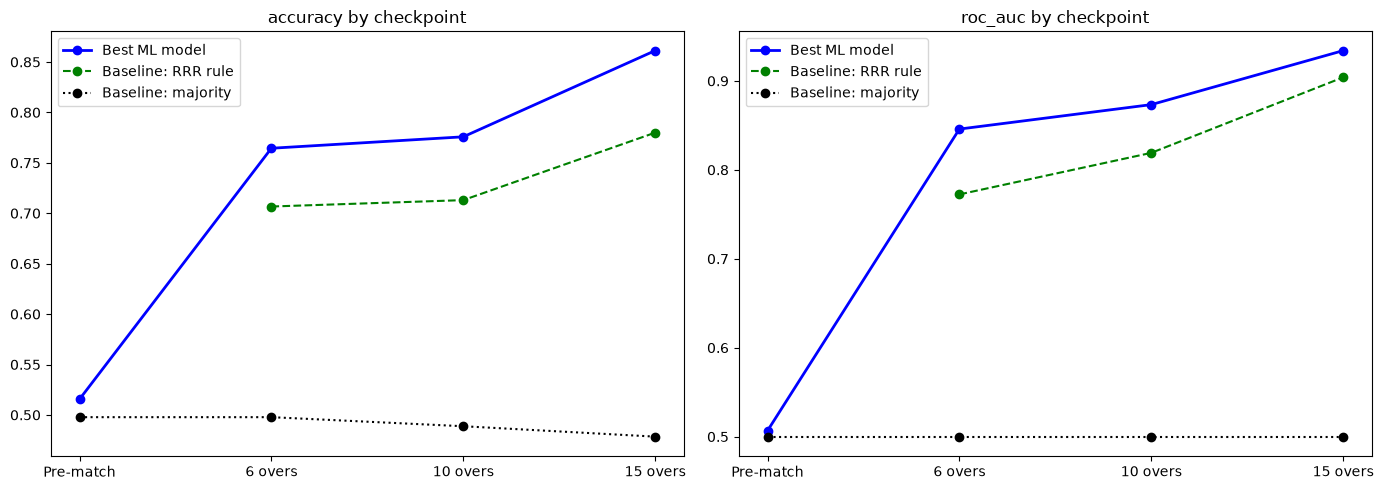

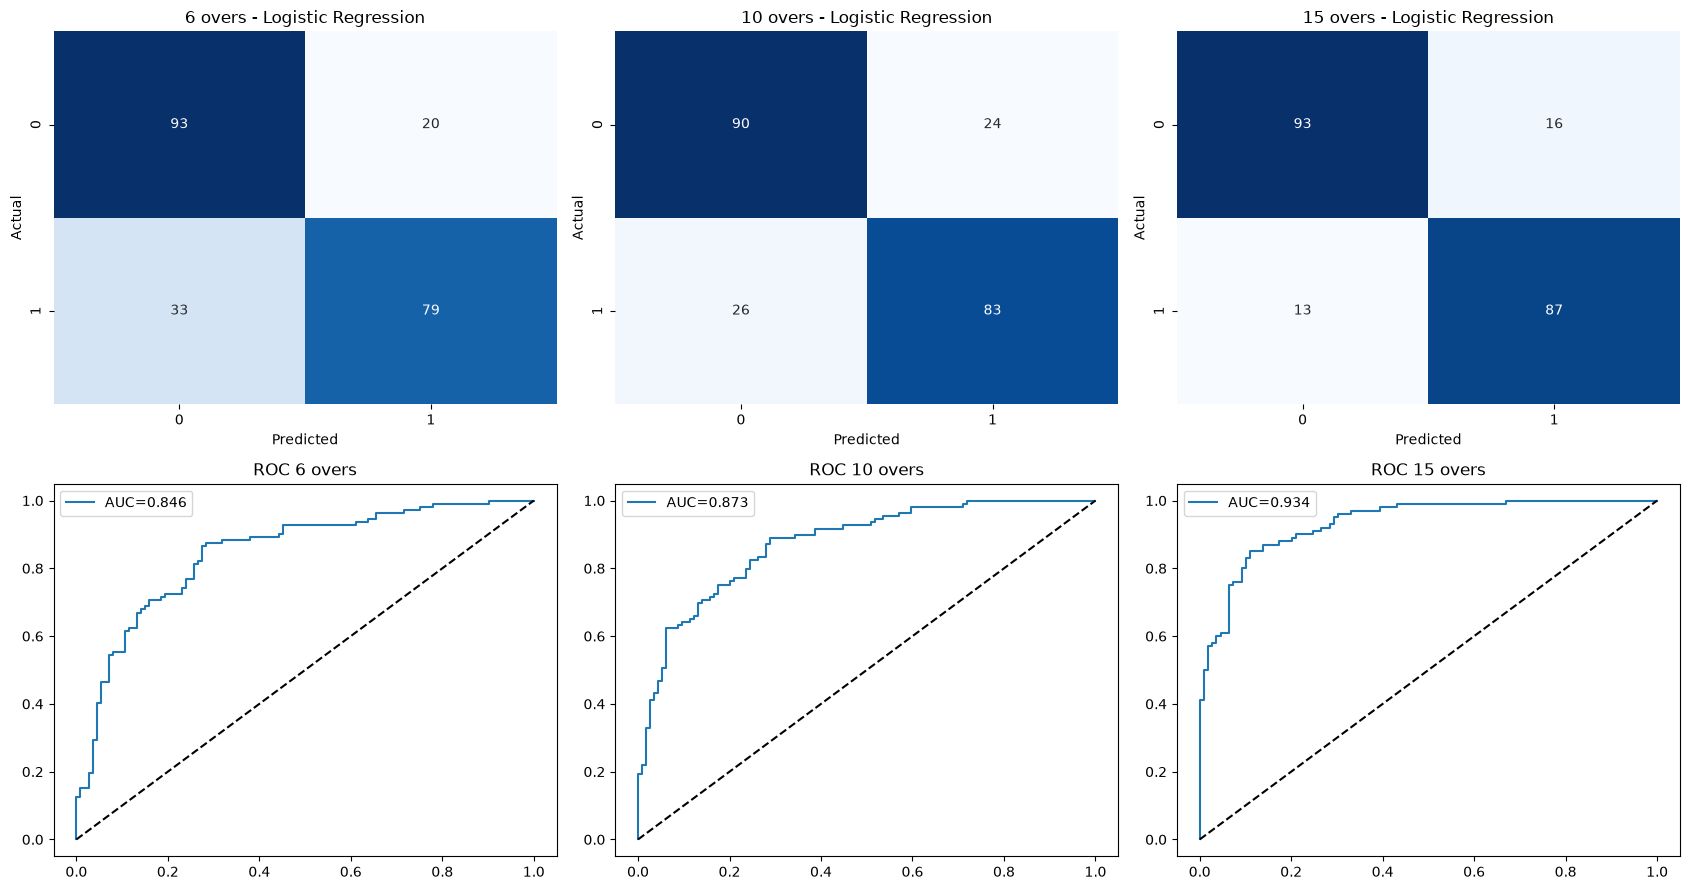

In [8]:
labels = ['Pre-match', '6 overs', '10 overs', '15 overs']
maj = clf_results[clf_results.model == 'Baseline: majority class'].set_index('checkpoint')
rule = clf_results[clf_results.model == 'Baseline: RRR rule'].set_index('checkpoint')
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, met in zip(ax, ['accuracy', 'roc_auc']):
    a.plot(labels, best[met].values, 'b-o', lw=2, label='Best ML model')
    a.plot(labels[1:], rule[met].values, 'g--o', label='Baseline: RRR rule')
    a.plot(labels, maj[met].values, 'k:o', label='Baseline: majority')
    a.set_title(f'{met} by checkpoint'); a.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for j, k in enumerate([6, 10, 15]):
    nm = best.loc[k, 'model']; m, f, Xte, y, pr, pc = store[(k, nm)]
    sns.heatmap(confusion_matrix(y, pc), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0, j]); ax[0, j].set_title(f'{k} overs - {nm}'); ax[0, j].set_xlabel('Predicted'); ax[0, j].set_ylabel('Actual')
    fpr, tpr, _ = roc_curve(y, pr); ax[1, j].plot(fpr, tpr, label=f'AUC={roc_auc_score(y, pr):.3f}'); ax[1, j].plot([0, 1], [0, 1], 'k--'); ax[1, j].legend(); ax[1, j].set_title(f'ROC {k} overs')
plt.tight_layout(); plt.show()

In [10]:
#Regression on the 2nd innings


 checkpoint                   model    MAE   RMSE     R2  MAE_lost_chases  n_test
          6    Baseline: train mean 31.898 39.275 -0.459           33.122     225
          6 Baseline: run-rate x 20 34.840 46.120 -1.012           30.274     225
          6  Baseline: target score 16.764 29.527  0.175           31.735     225
          6                   Ridge 15.921 20.136  0.616           17.647     225
          6       Gradient Boosting 14.862 21.908  0.546           18.875     225
         10    Baseline: train mean 31.321 38.750 -0.474           32.584     223
         10 Baseline: run-rate x 20 23.143 29.245  0.160           21.053     223
         10  Baseline: target score 17.130 29.886  0.123           31.939     223
         10                   Ridge 14.003 18.192  0.675           16.173     223
         10       Gradient Boosting 13.398 19.523  0.626           16.972     223
         15    Baseline: train mean 30.442 37.532 -0.578           31.846     209
         15 Base

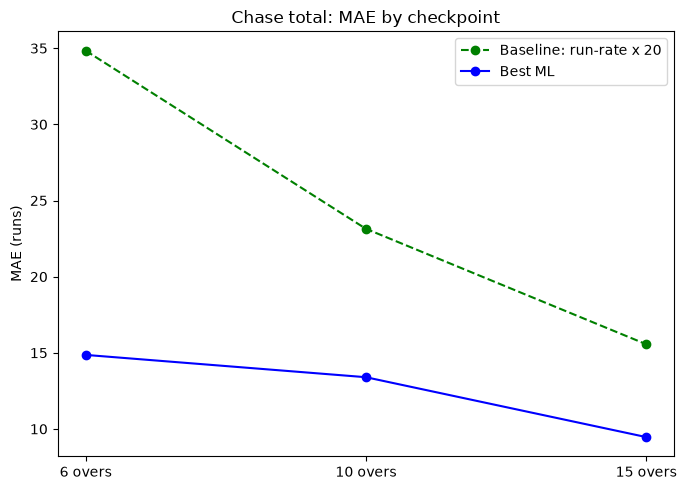

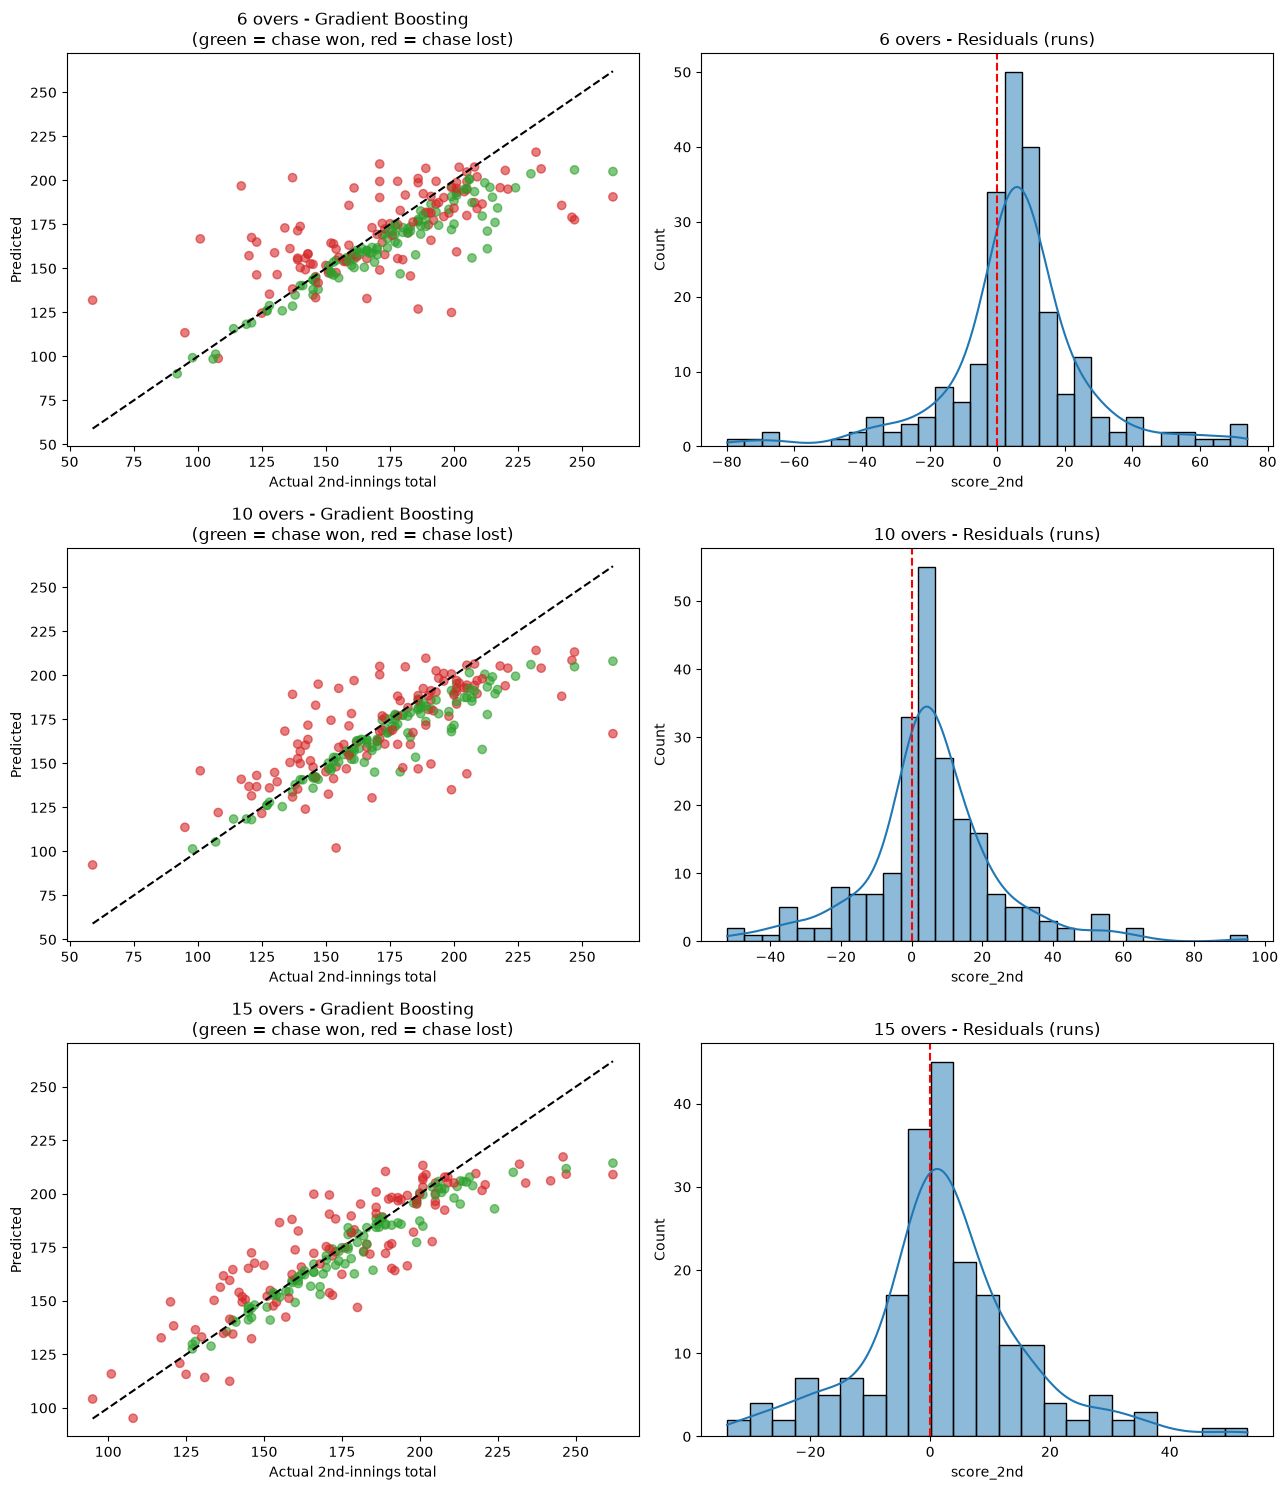

In [26]:
score_2nd_df = reg_df[reg_df.innings == 2].groupby('match_id')['runs_total'].sum().reset_index(name='score_2nd')

def build_chase_reg(k):
    return build_chase(k).merge(score_2nd_df, on='match_id')

RFEATS = STATE + CONTEXT
CHECKPOINTS = [6, 10, 15]
rrows, rstore = [], {}
for k in CHECKPOINTS:
    d = build_chase_reg(k); tr, te = split(d); ytr, yte = tr.score_2nd, te.score_2nd
    lost = (te.chasing_team_win == 0).to_numpy()
    preds = {'Baseline: train mean': DummyRegressor().fit(tr[RFEATS], ytr).predict(te[RFEATS]),
             'Baseline: run-rate x 20': (te.crr * 20).to_numpy(),
             'Baseline: target score': (te.score_1st + 1).to_numpy()}
    for nm, mdl in {'Ridge': make_pipeline(StandardScaler(), Ridge()),
                    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=3, random_state=42)}.items():
        mdl.fit(tr[RFEATS], ytr); preds[nm] = mdl.predict(te[RFEATS]); rstore[(k, nm)] = (mdl, RFEATS, te)
    for nm, p in preds.items():
        rrows.append(dict(checkpoint=k, model=nm, MAE=mean_absolute_error(yte, p), RMSE=np.sqrt(mean_squared_error(yte, p)),
                          R2=r2_score(yte, p), MAE_lost_chases=mean_absolute_error(yte[lost], p[lost]) if lost.any() else np.nan, n_test=len(te)))
reg_results = pd.DataFrame(rrows); print(reg_results.round(3).to_string(index=False))

ml = reg_results[~reg_results.model.str.startswith('Baseline')].sort_values('MAE').groupby('checkpoint').head(1).set_index('checkpoint').sort_index()
bl = reg_results[reg_results.model == 'Baseline: run-rate x 20'].set_index('checkpoint')
labels = [f'{k} overs' for k in CHECKPOINTS]

# --- Figure 1: MAE by checkpoint ---
plt.figure(figsize=(7, 5))
plt.plot(labels, bl.MAE.values, 'g--o', label='Baseline: run-rate x 20')
plt.plot(labels, ml.MAE.values, 'b-o', label='Best ML')
plt.ylabel('MAE (runs)'); plt.legend(); plt.title('Chase total: MAE by checkpoint')
plt.tight_layout(); plt.show()

# --- Figure 2: scatter + residuals for every checkpoint ---
fig, ax = plt.subplots(len(CHECKPOINTS), 2, figsize=(13, 5 * len(CHECKPOINTS)))
for i, k in enumerate(CHECKPOINTS):
    nm = ml.loc[k, 'model']; m, f, te = rstore[(k, nm)]; p = m.predict(te[f])
    cols = np.where(te.chasing_team_win == 1, '#2ca02c', '#d62728')

    ax[i, 0].scatter(te.score_2nd, p, c=cols, alpha=.6)
    lim = [min(te.score_2nd.min(), p.min()), max(te.score_2nd.max(), p.max())]
    ax[i, 0].plot(lim, lim, 'k--')
    ax[i, 0].set_xlabel('Actual 2nd-innings total'); ax[i, 0].set_ylabel('Predicted')
    ax[i, 0].set_title(f'{k} overs - {nm}\n(green = chase won, red = chase lost)')

    sns.histplot(te.score_2nd - p, kde=True, ax=ax[i, 1])
    ax[i, 1].axvline(0, color='r', ls='--')
    ax[i, 1].set_title(f'{k} overs - Residuals (runs)')
plt.tight_layout(); plt.show()

In [15]:
#K-Means venue clustering


Silhouette by k: {2: 0.401, 3: 0.431, 4: 0.379, 5: 0.377, 6: 0.357}


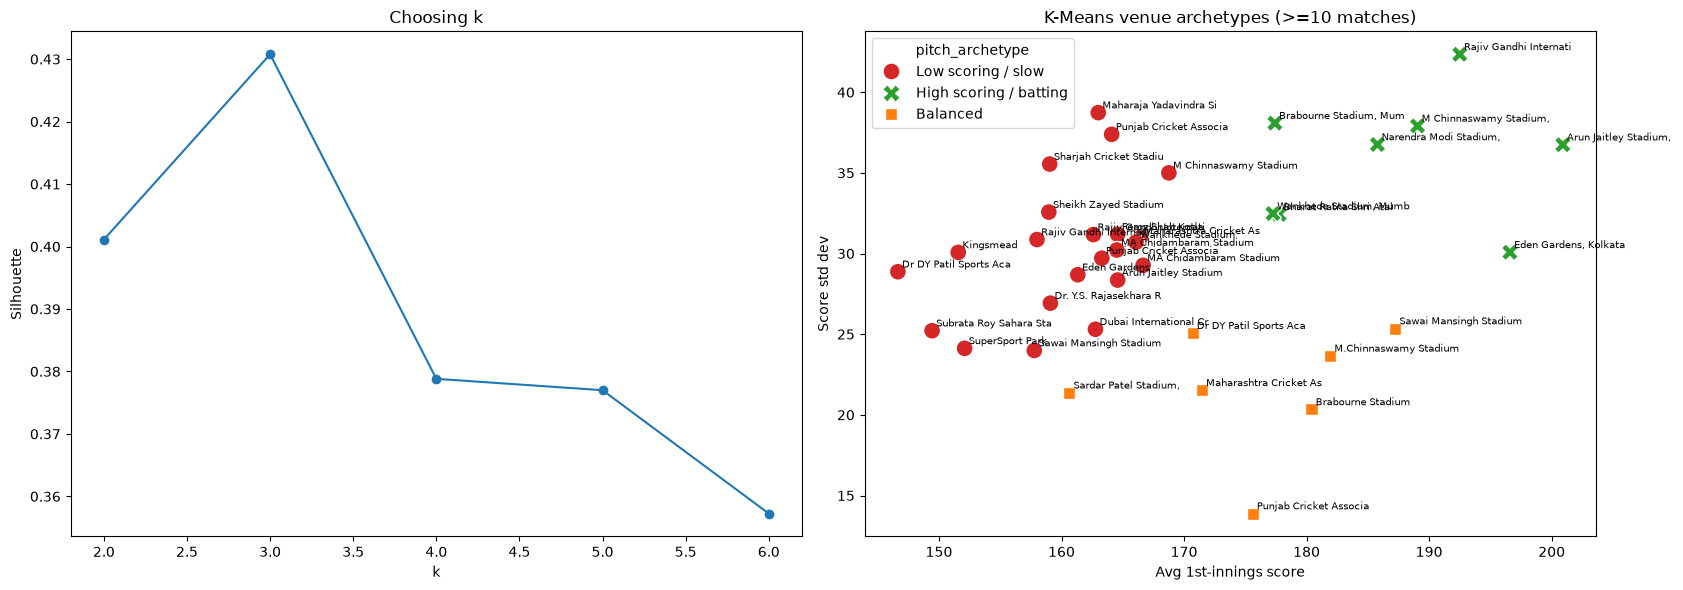

                        avg_score  score_std  chase_win_rate
pitch_archetype                                             
Balanced                   175.42      21.60            0.46
High scoring / batting     187.16      35.86            0.52
Low scoring / slow         160.51      30.22            0.55


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

vstats = base.groupby('venue').agg(avg_score=('score_1st', 'mean'), score_std=('score_1st', 'std'),
                                   chase_win_rate=('chasing_team_win', 'mean'), total_matches=('match_id', 'count')).reset_index()
vf = vstats[vstats.total_matches >= 10].dropna().copy()
Xv = StandardScaler().fit_transform(vf[['avg_score', 'score_std']])

sil = {k_: silhouette_score(Xv, KMeans(n_clusters=k_, random_state=42, n_init=10).fit_predict(Xv)) for k_ in range(2, min(7, len(vf)))}
print('Silhouette by k:', {k_: round(v, 3) for k_, v in sil.items()})

K_CLUSTERS = 3          # keep 3 for interpretability (low / balanced / high scoring); compare with the silhouette above
vf['cluster'] = KMeans(n_clusters=K_CLUSTERS, random_state=42, n_init=10).fit_predict(Xv)
order = vf.groupby('cluster')['avg_score'].mean().sort_values().index
vf['pitch_archetype'] = vf['cluster'].map(dict(zip(order, ['Low scoring / slow', 'Balanced', 'High scoring / batting']))) 

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ax[0].plot(list(sil), list(sil.values()), 'o-'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Silhouette'); ax[0].set_title('Choosing k')
sns.scatterplot(data=vf, x='avg_score', y='score_std', hue='pitch_archetype', style='pitch_archetype', s=150,
                palette={'Low scoring / slow': '#d62728', 'Balanced': '#ff7f0e', 'High scoring / batting': '#2ca02c'}, ax=ax[1])
for _, r in vf.iterrows(): ax[1].annotate(r.venue[:22], (r.avg_score, r.score_std), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax[1].set_xlabel('Avg 1st-innings score'); ax[1].set_ylabel('Score std dev'); ax[1].set_title('K-Means venue archetypes (>=10 matches)')
plt.tight_layout(); plt.show()
print(vf.groupby('pitch_archetype')[['avg_score', 'score_std', 'chase_win_rate']].mean().round(2))

In [17]:
#SHAP for the 6, 10 and 15-over chase models


PermutationExplainer explainer: 151it [00:21,  7.02it/s]                         


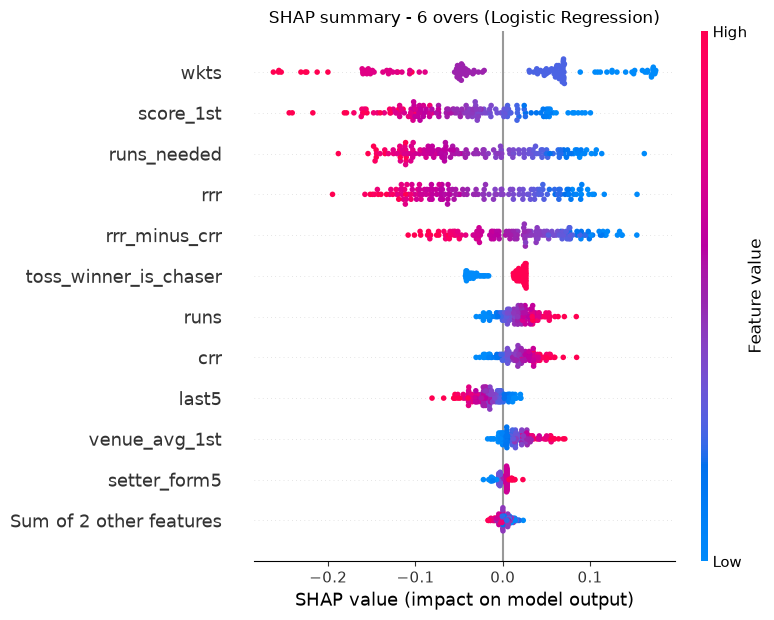

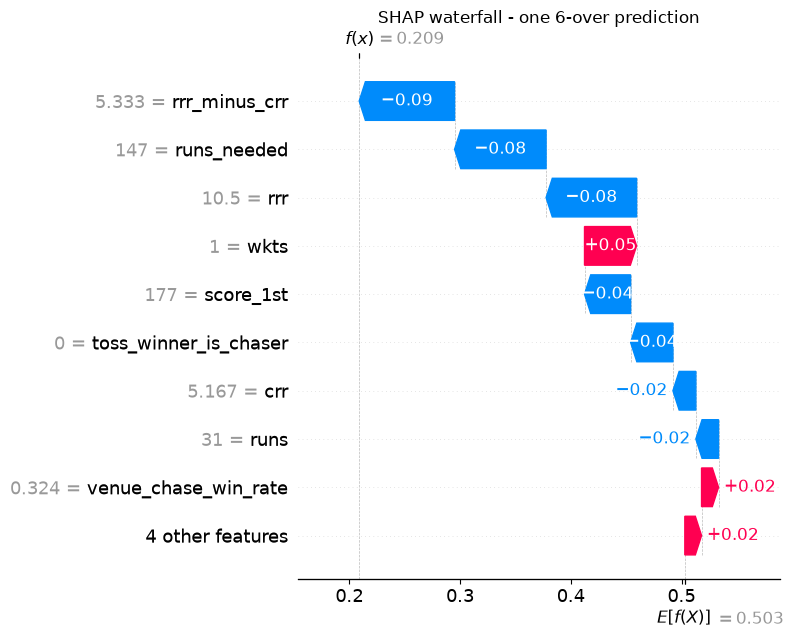

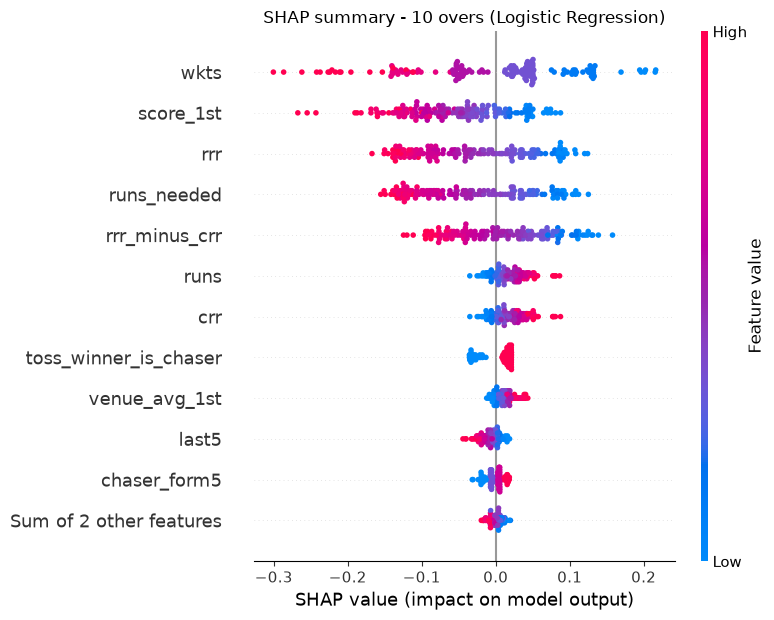

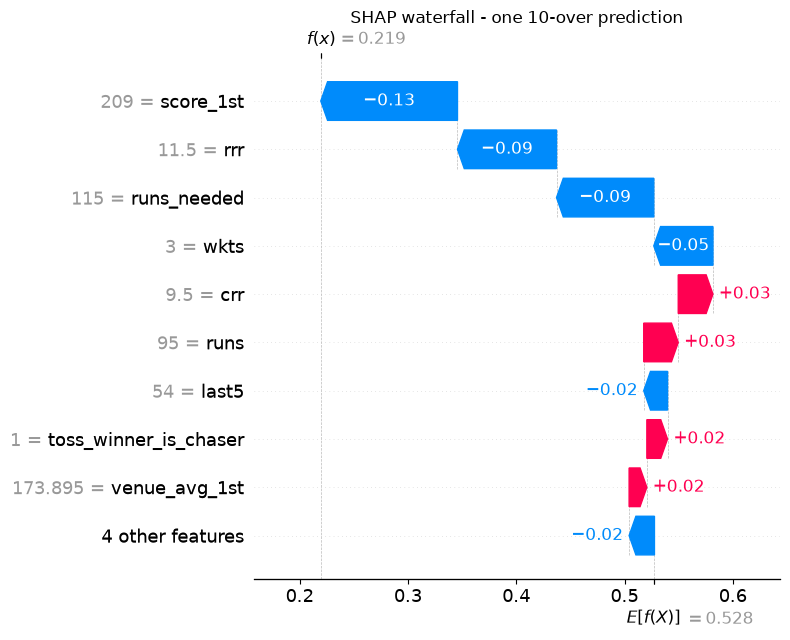

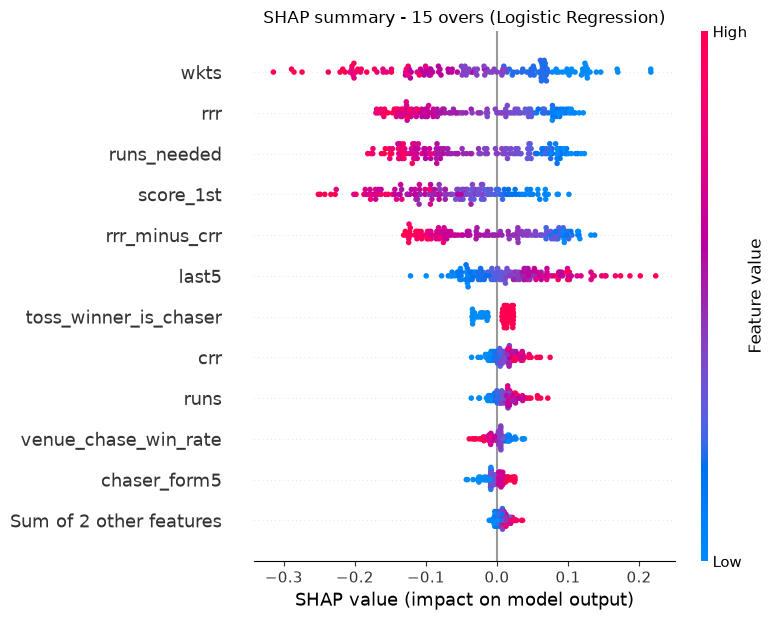

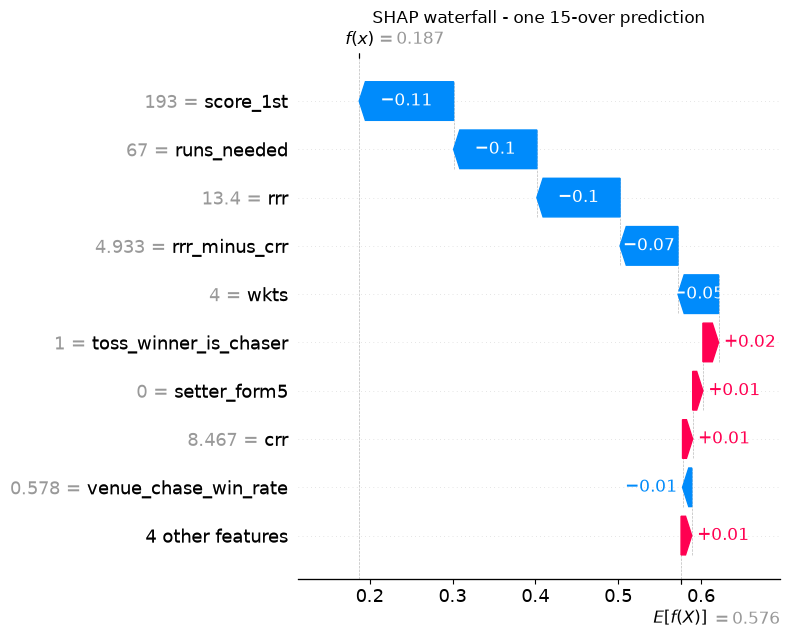

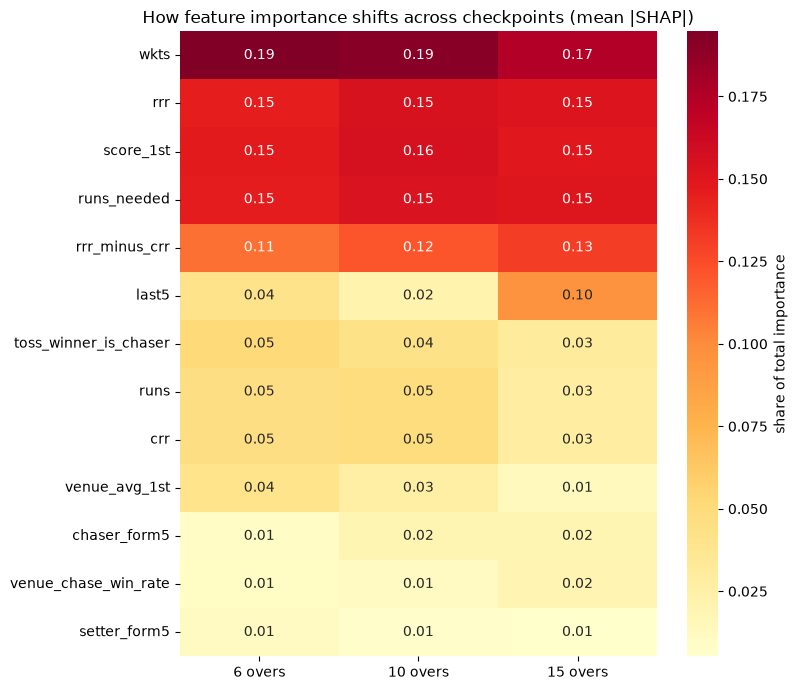

In [18]:
from sklearn.inspection import permutation_importance
try:
    import shap
    HAVE_SHAP = True
except ImportError:
    HAVE_SHAP = False
    print('shap not installed -> using permutation importance fallback (pip install shap for the SHAP plots)')

# training sets + training-period medians of the context features (also used by the live predictor)
train_sets, ctx_med = {}, {}
for k in [6, 10, 15]:
    tr_, _ = split(build_chase(k)); train_sets[k] = tr_; ctx_med[k] = {c: float(tr_[c].median()) for c in CONTEXT}

imp_table, shap_store = {}, {}
for k in [6, 10, 15]:
    nm = best.loc[k, 'model']; m, f, Xte, y, pr, pc = store[(k, nm)]
    if HAVE_SHAP:
        predict_fn = lambda X, m=m, f=f: m.predict_proba(pd.DataFrame(X, columns=f))[:, 1]
        masker = shap.maskers.Independent(train_sets[k][f].sample(min(100, len(train_sets[k])), random_state=42))
        sv = shap.Explainer(predict_fn, masker, algorithm='permutation')(Xte.iloc[:150])
        shap_store[k] = sv
        imp_table[k] = pd.Series(np.abs(sv.values).mean(0), index=f)
        shap.plots.beeswarm(sv, show=False, max_display=12); plt.title(f'SHAP summary - {k} overs ({nm})'); plt.tight_layout(); plt.show()
        shap.plots.waterfall(sv[0], show=False); plt.title(f'SHAP waterfall - one {k}-over prediction'); plt.tight_layout(); plt.show()
    else:
        pi = permutation_importance(m, Xte, y, scoring='roc_auc', n_repeats=20, random_state=42)
        imp_table[k] = pd.Series(pi.importances_mean, index=f)

imp_df = pd.DataFrame(imp_table).rename(columns=lambda k: f'{k} overs')
imp_df = imp_df.loc[imp_df.mean(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(8, 7))
sns.heatmap(imp_df / imp_df.sum(), annot=True, fmt='.2f', cmap='YlOrRd', cbar_kws={'label': 'share of total importance'})
plt.title(f'How feature importance shifts across checkpoints ({"mean |SHAP|" if HAVE_SHAP else "permutation importance"})')
plt.tight_layout(); plt.show()

In [12]:
# Live predictor for 6 / 10 / 15 overs (replaces `predict_live_chase`, uses the corrected models)

After  6 ov: 48/1 chasing 191 | need 143 @ 10.21 rpo (CRR 8.00) | chase win  36.1%  [Logistic Regression]
After 10 ov: 85/3 chasing 191 | need 106 @ 10.60 rpo (CRR 8.50) | chase win  30.3%  [Logistic Regression]
After 15 ov: 120/5 chasing 191 | need 71 @ 14.20 rpo (CRR 8.00) | chase win   8.0%  [Logistic Regression]


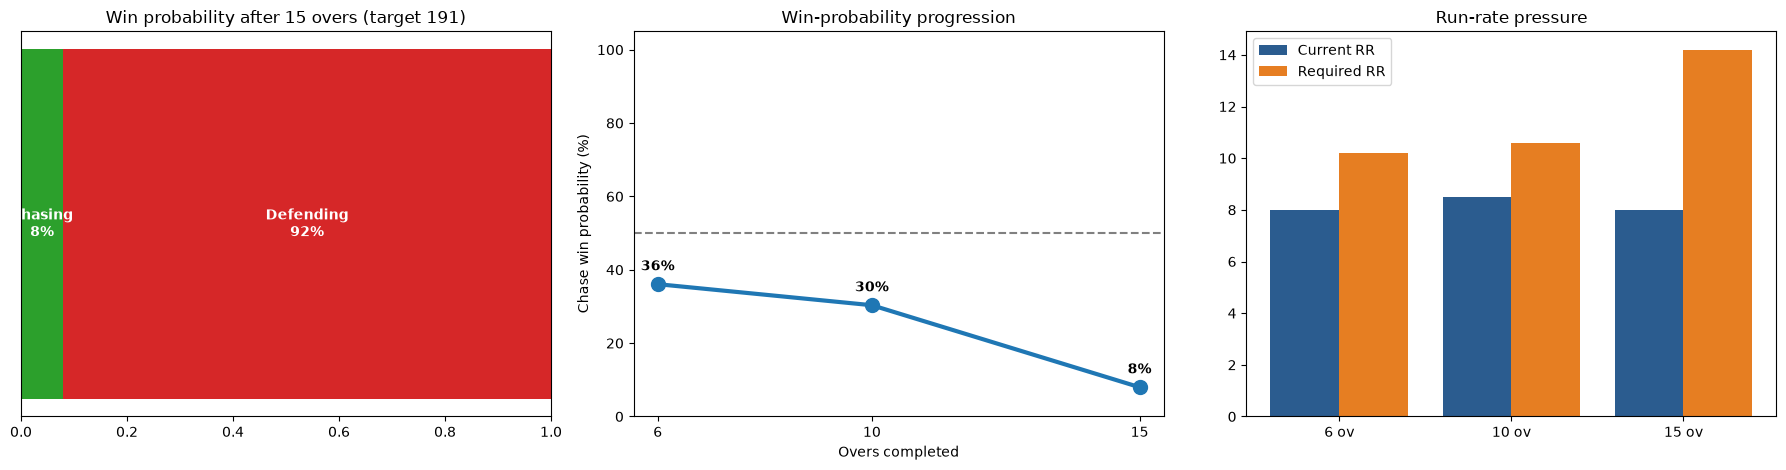

After  6 ov: 55/1 chasing 151 | need 96 @ 6.86 rpo (CRR 9.17) | chase win  86.7%  [Logistic Regression]
After 10 ov: 100/1 chasing 151 | need 51 @ 5.10 rpo (CRR 10.00) | chase win  97.4%  [Logistic Regression]
After 15 ov: 128/2 chasing 151 | need 23 @ 4.60 rpo (CRR 8.53) | chase win  98.8%  [Logistic Regression]


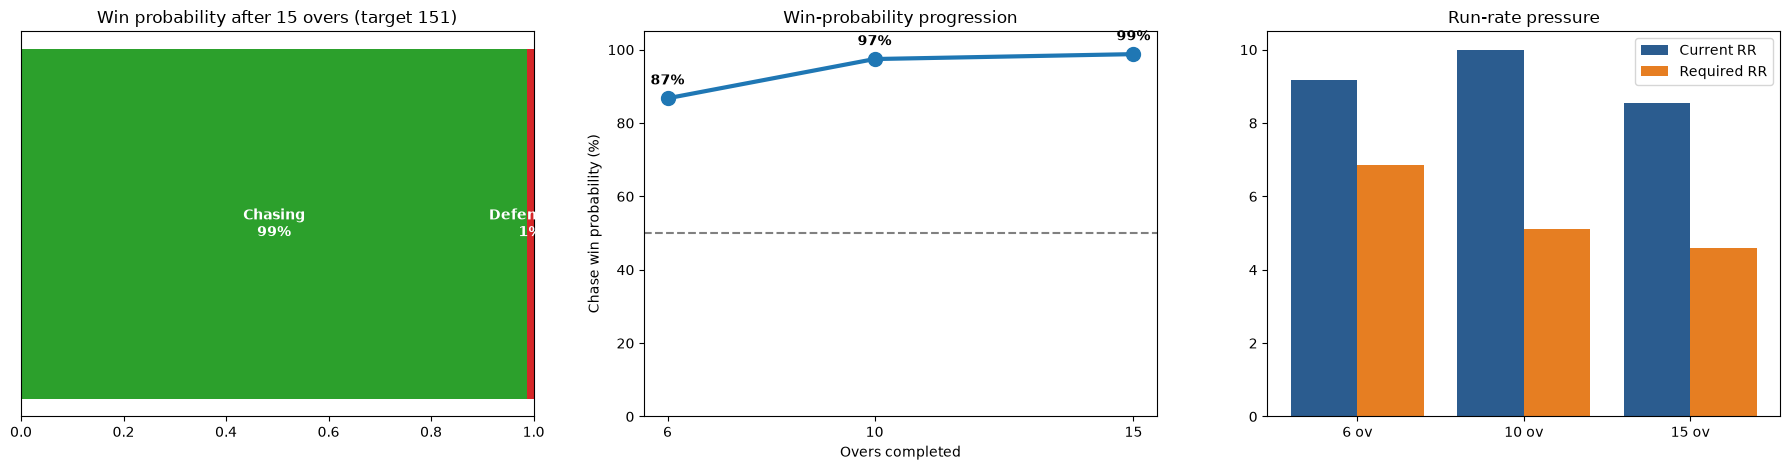

[0.8674172269706041, 0.9744760479318866, 0.9878424561459161]

In [19]:
def _frame(overs, score_1st, runs, wkts, last5=None):
    s, r, w = np.broadcast_arrays(*[np.atleast_1d(np.asarray(a, dtype=float)) for a in (score_1st, runs, wkts)])
    need = s + 1 - r
    d = pd.DataFrame({'runs': r, 'wkts': w, 'runs_needed': need, 'score_1st': s, 'crr': r / overs, 'rrr': need / (20 - overs)})
    d['rrr_minus_crr'] = d.rrr - d.crr
    d['last5'] = r * min(5, overs) / overs if last5 is None else last5
    for c, v in ctx_med[overs].items(): d[c] = v          # venue / form context -> training medians
    return d[STATE + CONTEXT]

def live_proba(overs, score_1st, runs, wkts, last5=None):
    """Chase win probability (vectorised). Chase already won (runs needed <= 0) -> 1."""
    m = store[(overs, best.loc[overs, 'model'])][0]
    fr = _frame(overs, score_1st, runs, wkts, last5)
    p = m.predict_proba(fr)[:, 1]
    return np.where(fr.runs_needed.to_numpy() <= 0, 1.0, p)

def predict_live_chase(score_1st, state, show=True):
    """state = {6: (runs, wkts), 10: (runs, wkts), 15: (runs, wkts)} - give any subset. Prints a summary and draws the live panel."""
    ks = sorted(state)
    probs = [float(live_proba(k, score_1st, *state[k])[0]) for k in ks]
    for k, p in zip(ks, probs):
        r, w = state[k]; need = score_1st + 1 - r
        print(f'After {k:>2} ov: {r}/{w} chasing {score_1st + 1} | need {need} @ {need / (20 - k):.2f} rpo (CRR {r / k:.2f}) | '
              f'chase win {p * 100:5.1f}%  [{best.loc[k, "model"]}]')
    if not show: return probs
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    # (a) gauge-style bar for the latest checkpoint
    p = probs[-1]; ax[0].barh([0], [p], color='#2ca02c'); ax[0].barh([0], [1 - p], left=[p], color='#d62728')
    ax[0].text(p / 2, 0, f'Chasing\n{p * 100:.0f}%', ha='center', va='center', color='w', fontweight='bold')
    ax[0].text(p + (1 - p) / 2, 0, f'Defending\n{(1 - p) * 100:.0f}%', ha='center', va='center', color='w', fontweight='bold')
    ax[0].set_xlim(0, 1); ax[0].set_yticks([]); ax[0].set_title(f'Win probability after {ks[-1]} overs (target {score_1st + 1})')
    # (b) win-probability progression
    ax[1].plot(ks, np.array(probs) * 100, 'o-', lw=3, ms=10, color='#1f77b4'); ax[1].axhline(50, color='gray', ls='--')
    for k, p_ in zip(ks, probs): ax[1].annotate(f'{p_ * 100:.0f}%', (k, p_ * 100), xytext=(0, 10), textcoords='offset points', ha='center', fontweight='bold')
    ax[1].set_ylim(0, 105); ax[1].set_xticks(ks); ax[1].set_xlabel('Overs completed'); ax[1].set_ylabel('Chase win probability (%)'); ax[1].set_title('Win-probability progression')
    # (c) required vs current run rate
    crr = [state[k][0] / k for k in ks]; rrr = [(score_1st + 1 - state[k][0]) / (20 - k) for k in ks]; x = np.arange(len(ks))
    ax[2].bar(x - .2, crr, .4, label='Current RR', color='#2b5c8f'); ax[2].bar(x + .2, rrr, .4, label='Required RR', color='#e67e22')
    ax[2].set_xticks(x); ax[2].set_xticklabels([f'{k} ov' for k in ks]); ax[2].set_title('Run-rate pressure'); ax[2].legend()
    plt.tight_layout(); plt.show(); return probs

predict_live_chase(190, {6: (48, 1), 10: (85, 3), 15: (120, 5)})     # high-pressure chase
predict_live_chase(150, {6: (55, 1), 10: (100, 1), 15: (128, 2)})    # comfortable chase

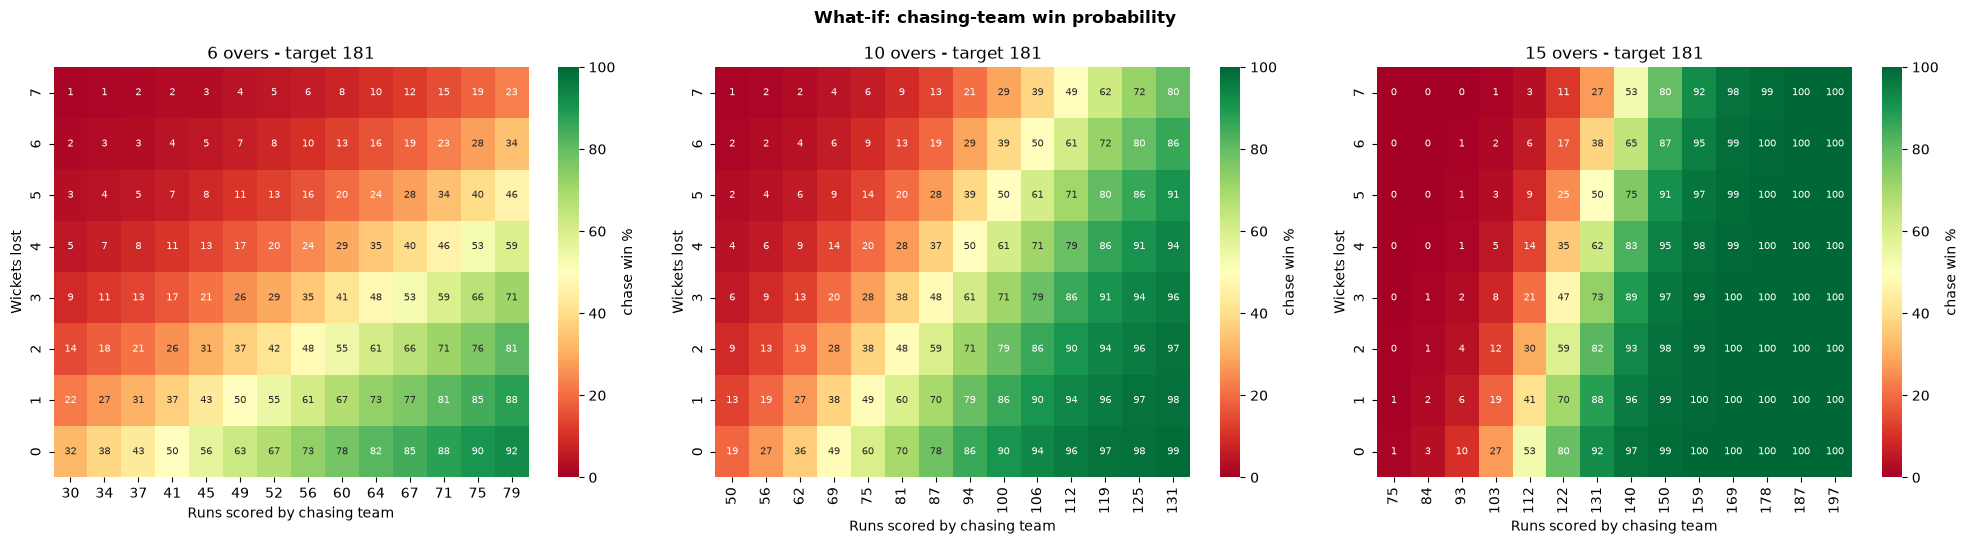

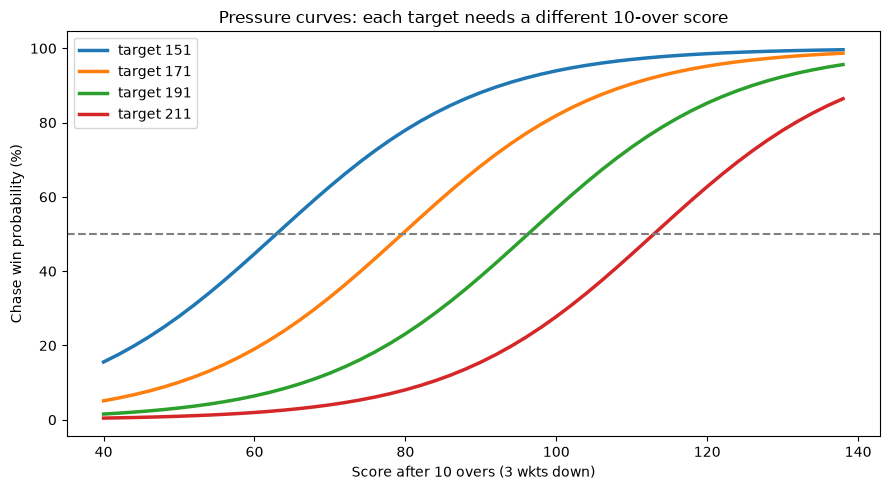

In [20]:
def whatif_heatmaps(score_1st, max_wkts=7):
    fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
    for a, k in zip(ax, [6, 10, 15]):
        par = (score_1st + 1) * k / 20
        runs = np.round(np.linspace(par * 0.55, par * 1.45, 14)).astype(int); wk = np.arange(0, max_wkts + 1)
        R, W = np.meshgrid(runs, wk)
        P = live_proba(k, score_1st, R.ravel(), W.ravel()).reshape(R.shape) * 100
        sns.heatmap(pd.DataFrame(P, index=wk, columns=runs), cmap='RdYlGn', vmin=0, vmax=100, annot=True, fmt='.0f', annot_kws={'size': 7},
                    cbar_kws={'label': 'chase win %'}, ax=a)
        a.set_title(f'{k} overs - target {score_1st + 1}'); a.set_xlabel('Runs scored by chasing team'); a.set_ylabel('Wickets lost'); a.invert_yaxis()
    plt.suptitle('What-if: chasing-team win probability', fontweight='bold'); plt.tight_layout(); plt.show()
whatif_heatmaps(180)

# sensitivity: win % vs score at 10 overs for different targets (3 wickets down)
plt.figure(figsize=(9, 5))
for tgt in [150, 170, 190, 210]:
    rr = np.arange(40, 140, 2); plt.plot(rr, live_proba(10, tgt, rr, 3) * 100, lw=2.5, label=f'target {tgt + 1}')
plt.axhline(50, color='gray', ls='--'); plt.xlabel('Score after 10 overs (3 wkts down)'); plt.ylabel('Chase win probability (%)')
plt.title('Pressure curves: each target needs a different 10-over score'); plt.legend(); plt.tight_layout(); plt.show()

In [21]:
#Replay real test-set matches – how the model's belief evolved vs the real result

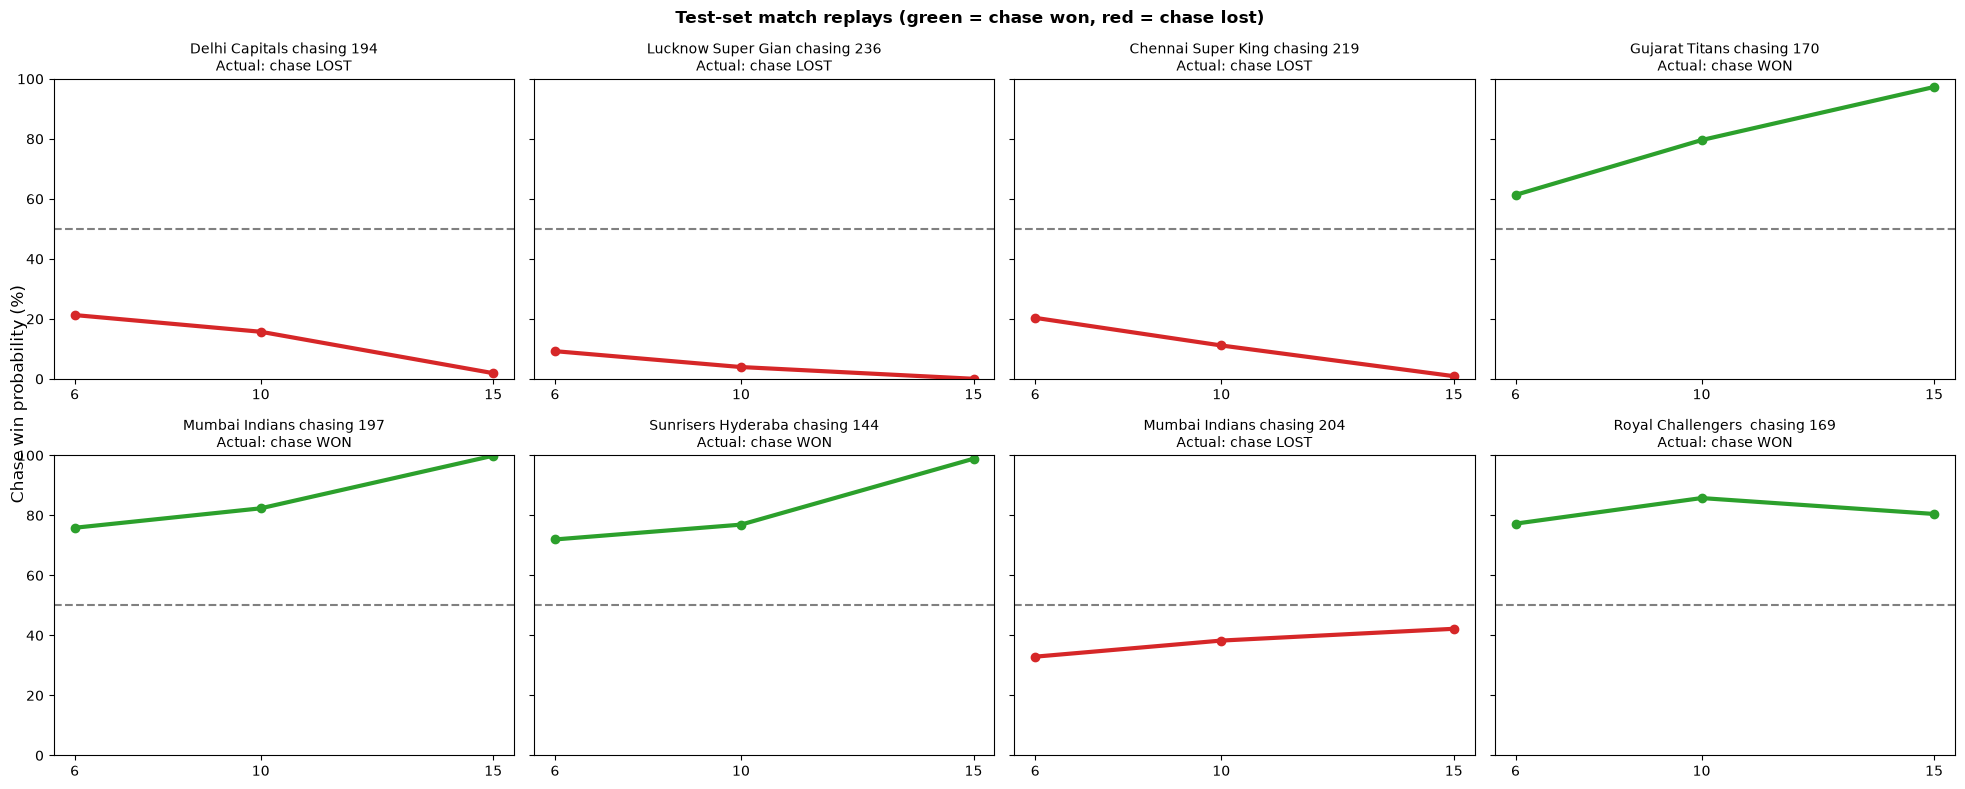

In [22]:
probs_by_k = {k: pd.Series(store[(k, best.loc[k, 'model'])][4], index=store[(k, best.loc[k, 'model'])][2].index) for k in [6, 10, 15]}
common = probs_by_k[6].index.intersection(probs_by_k[10].index).intersection(probs_by_k[15].index)
pick = pd.Index(np.random.RandomState(7).choice(common, size=min(8, len(common)), replace=False))
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharey=True)
for a, ix in zip(axes.ravel(), pick):
    r = base.loc[ix]; pp = [probs_by_k[k].loc[ix] * 100 for k in [6, 10, 15]]
    a.plot([6, 10, 15], pp, 'o-', lw=3, color='#2ca02c' if r.chasing_team_win else '#d62728'); a.axhline(50, color='gray', ls='--')
    a.set_title(f'{str(r.chasing_team)[:18]} chasing {int(r.score_1st) + 1}\nActual: chase {"WON" if r.chasing_team_win else "LOST"}', fontsize=10)
    a.set_xticks([6, 10, 15]); a.set_ylim(0, 100)
fig.supylabel('Chase win probability (%)'); fig.suptitle('Test-set match replays (green = chase won, red = chase lost)', fontweight='bold'); plt.tight_layout(); plt.show()

In [23]:
#Dashboard-style summary

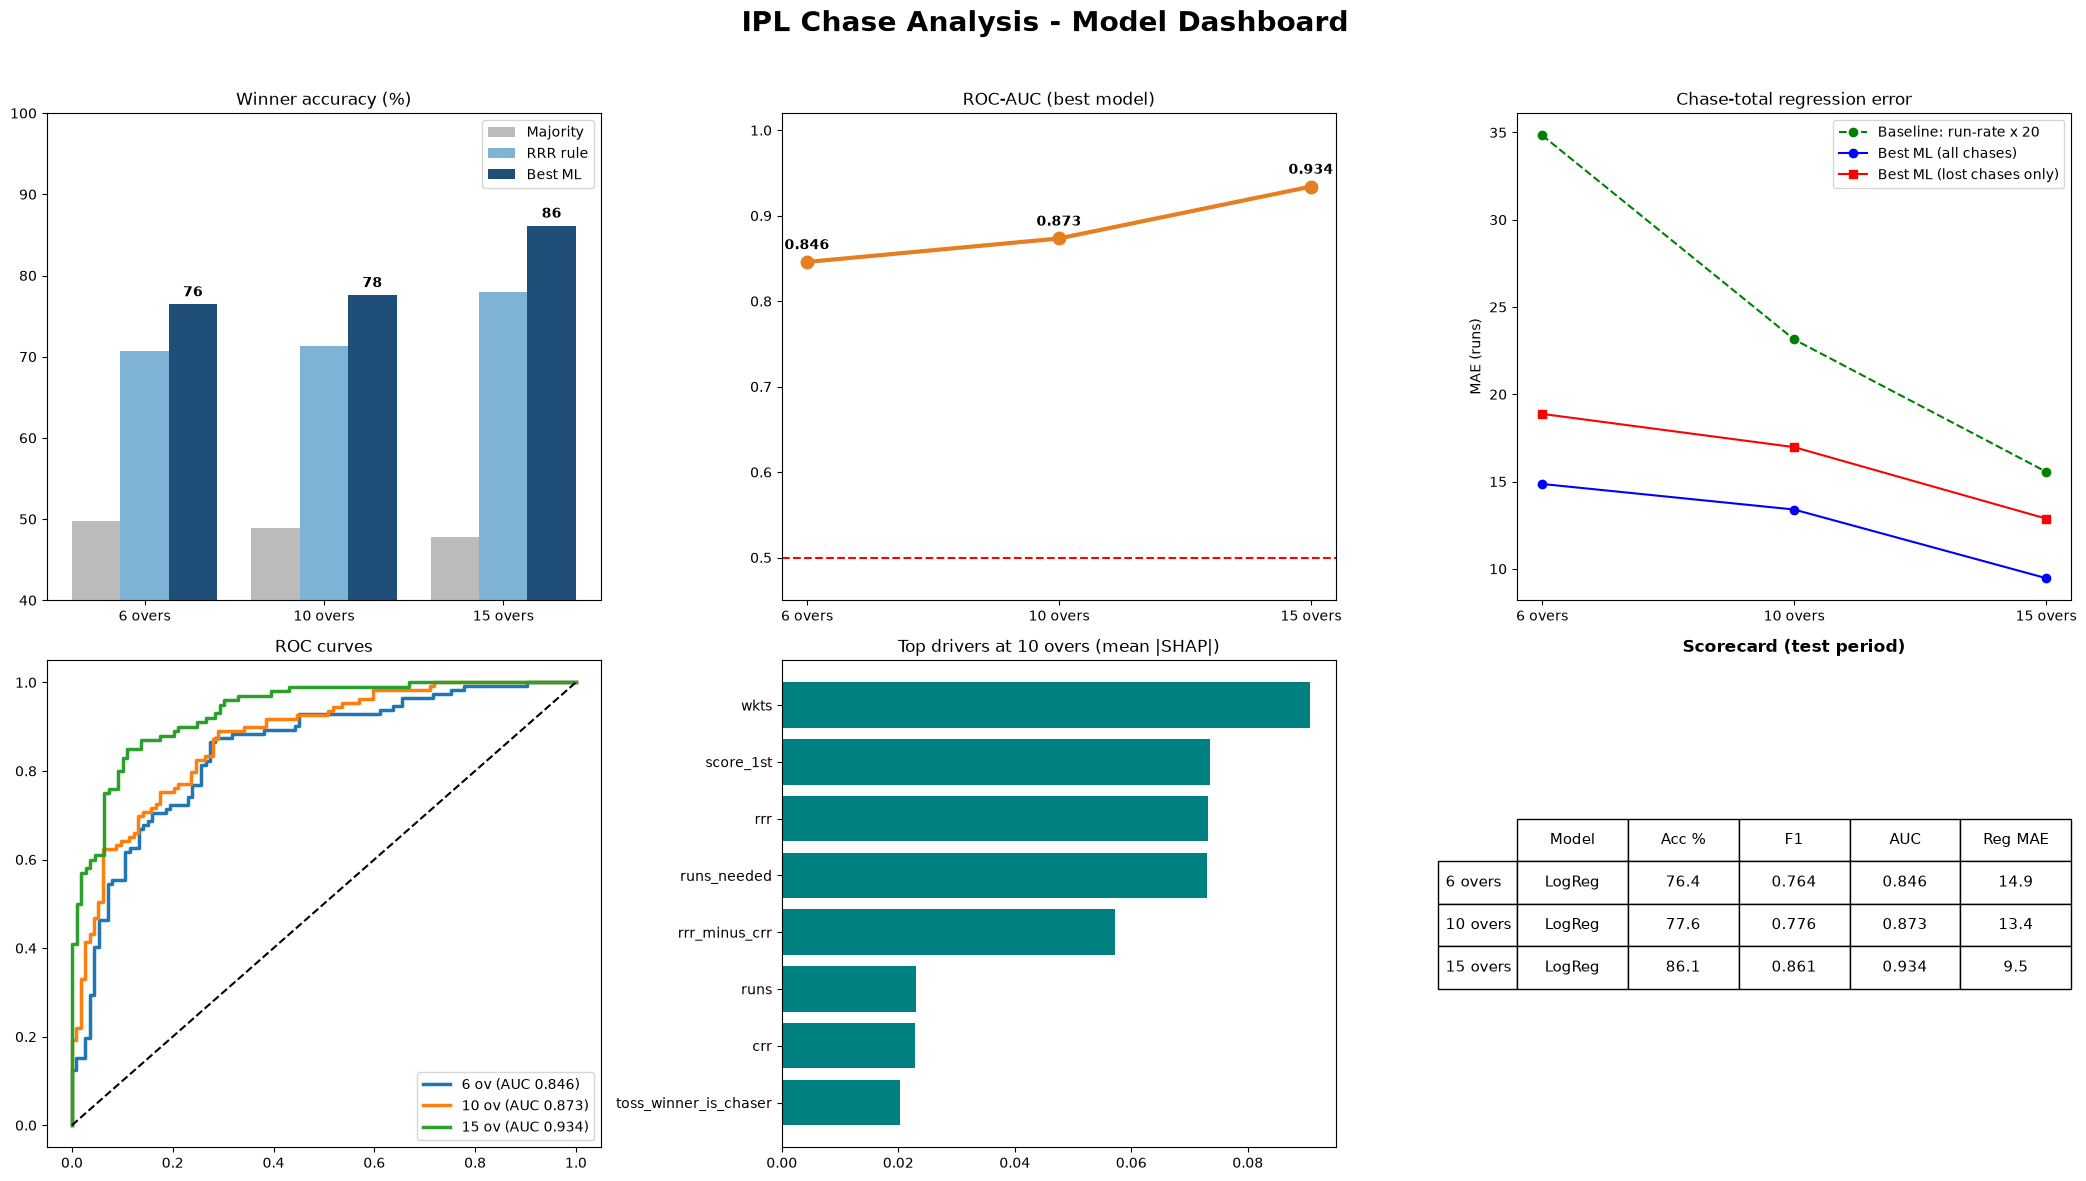

In [24]:
cp = ['6 overs', '10 overs', '15 overs']; bb = best.loc[[6, 10, 15]]
fig = plt.figure(figsize=(21, 12)); gs = fig.add_gridspec(2, 3)
a1 = fig.add_subplot(gs[0, 0]); a2 = fig.add_subplot(gs[0, 1]); a3 = fig.add_subplot(gs[0, 2]); a4 = fig.add_subplot(gs[1, 0]); a5 = fig.add_subplot(gs[1, 1]); a6 = fig.add_subplot(gs[1, 2])

x = np.arange(3); w = .27
a1.bar(x - w, maj.loc[[6, 10, 15], 'accuracy'] * 100, w, label='Majority', color='#bbbbbb'); a1.bar(x, rule.loc[[6, 10, 15], 'accuracy'] * 100, w, label='RRR rule', color='#7fb3d5')
a1.bar(x + w, bb.accuracy * 100, w, label='Best ML', color='#1f4e79'); a1.set_xticks(x); a1.set_xticklabels(cp); a1.set_ylim(40, 100); a1.set_title('Winner accuracy (%)'); a1.legend()
for i, v in enumerate(bb.accuracy * 100): a1.text(i + w, v + 1, f'{v:.0f}', ha='center', fontweight='bold')

a2.plot(cp, bb.roc_auc.values, 'o-', lw=3, color='#e67e22', ms=9); a2.axhline(0.5, color='r', ls='--'); a2.set_ylim(0.45, 1.02); a2.set_title('ROC-AUC (best model)')
for i, v in enumerate(bb.roc_auc): a2.text(i, v + .015, f'{v:.3f}', ha='center', fontweight='bold')

a3.plot(cp, bl.loc[[6, 10, 15], 'MAE'].values, 'g--o', label='Baseline: run-rate x 20'); a3.plot(cp, ml.loc[[6, 10, 15], 'MAE'].values, 'b-o', label='Best ML (all chases)')
a3.plot(cp, ml.loc[[6, 10, 15], 'MAE_lost_chases'].values, 'r-s', label='Best ML (lost chases only)'); a3.set_ylabel('MAE (runs)'); a3.set_title('Chase-total regression error'); a3.legend()

for k, c in zip([6, 10, 15], ['#1f77b4', '#ff7f0e', '#2ca02c']):
    _, _, _, y_, pr_, _ = store[(k, best.loc[k, 'model'])]; fpr, tpr, _ = roc_curve(y_, pr_); a4.plot(fpr, tpr, lw=2.5, color=c, label=f'{k} ov (AUC {roc_auc_score(y_, pr_):.3f})')
a4.plot([0, 1], [0, 1], 'k--'); a4.set_title('ROC curves'); a4.legend(loc='lower right')

top = imp_df['10 overs'].sort_values().tail(8); a5.barh(top.index, top.values, color='teal'); a5.set_title(f'Top drivers at 10 overs ({"mean |SHAP|" if HAVE_SHAP else "permutation"})')

a6.axis('off'); tbl = pd.DataFrame({'Model': bb.model.replace({'Logistic Regression': 'LogReg', 'Random Forest': 'RF', 'Gradient Boosting': 'GB'}).values, 'Acc %': (bb.accuracy * 100).round(1).values, 'F1': bb.f1_macro.round(3).values,
                                    'AUC': bb.roc_auc.round(3).values, 'Reg MAE': ml.loc[[6, 10, 15], 'MAE'].round(1).values}, index=cp)
t = a6.table(cellText=tbl.values, rowLabels=tbl.index, colLabels=tbl.columns, loc='center', cellLoc='center'); t.auto_set_font_size(False); t.set_fontsize(11); t.scale(1, 2.2)
a6.set_title('Scorecard (test period)', fontweight='bold')
fig.suptitle('IPL Chase Analysis - Model Dashboard', fontsize=20, fontweight='bold'); plt.tight_layout(rect=[0, 0, 1, .96]); plt.savefig('dashboard.png', dpi=150); plt.show()

clf_results.to_csv('classification_results.csv', index=False); reg_results.to_csv('chase_regression_results.csv', index=False)
base.to_csv('matches_clean.csv', index=False)